# 🔭 Lab 01: Trace-Based Evaluation Setup

## Module 01: Modern AI Evaluation Foundations 🧱

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/1_TraceBasedEvalSetup_STUDENT.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 30 min core (Tasks 1–7) · +40 min extended (Tasks 8–12) · +30 min for the five 🏆 challenges |
| 🎚️ **Level** | Foundations: no prior tracing experience needed |
| 🔑 **Keys needed** | **None to run.** A free Langfuse Cloud account (Task 1) is recommended so you can explore traces in the UI. Without keys the lab runs in *local mode*. An OpenAI key is optional (Task 11 only). |
| 🧰 **Tools** | `langfuse` v5 Python SDK (built on OpenTelemetry) · `pandas` · `matplotlib` · optional `openai` (Responses API) |
| 🏁 **You'll leave with** | Traced requests with scores attached, a p50-vs-p95 latency report, a root-caused retrieval bug, and an evidence-based ship decision |

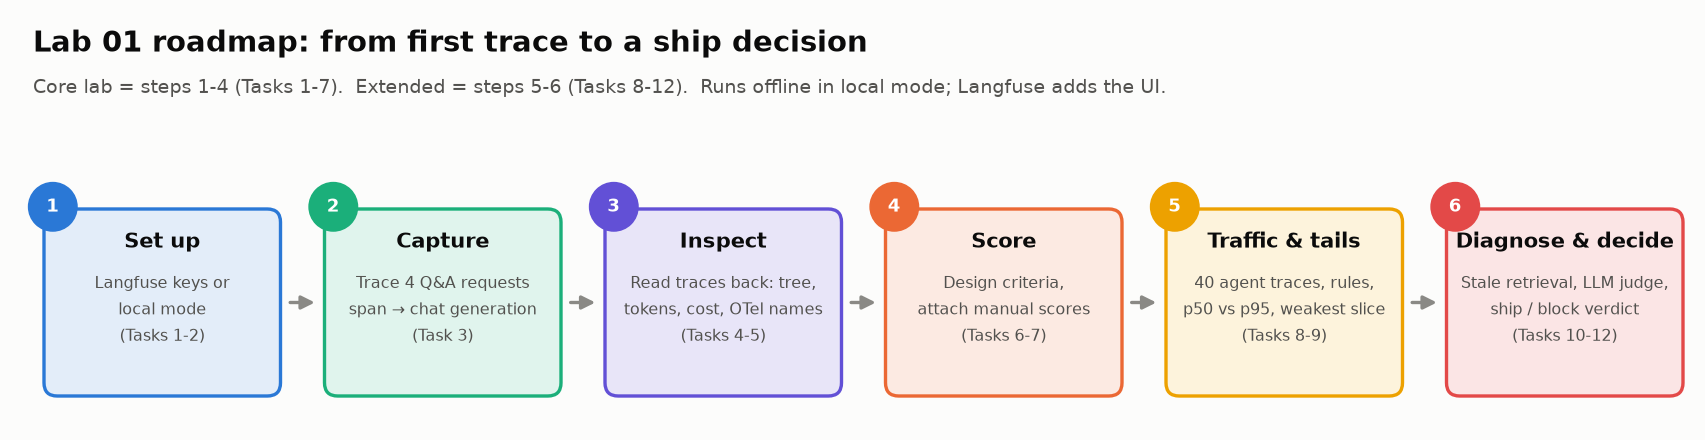

<sub>🖼️ *Your path through this lab*</sub>

---

> ### 🕵️ The case
>
> On Tuesday morning the docs assistant answered **40 customer requests**. A reviewer read every answer and signed off: *"Reads well. Ship the new version."*
>
> Every one of those requests also left a **trace**: which documents were retrieved, which tools ran, which calls failed and were retried, how long each step took, and what it cost.
>
> **Would you ship on the reviewer's word?** In Task 12 you'll make that call with evidence. On the way you'll count how many "reads well" answers were hiding a problem that only the trace could show.

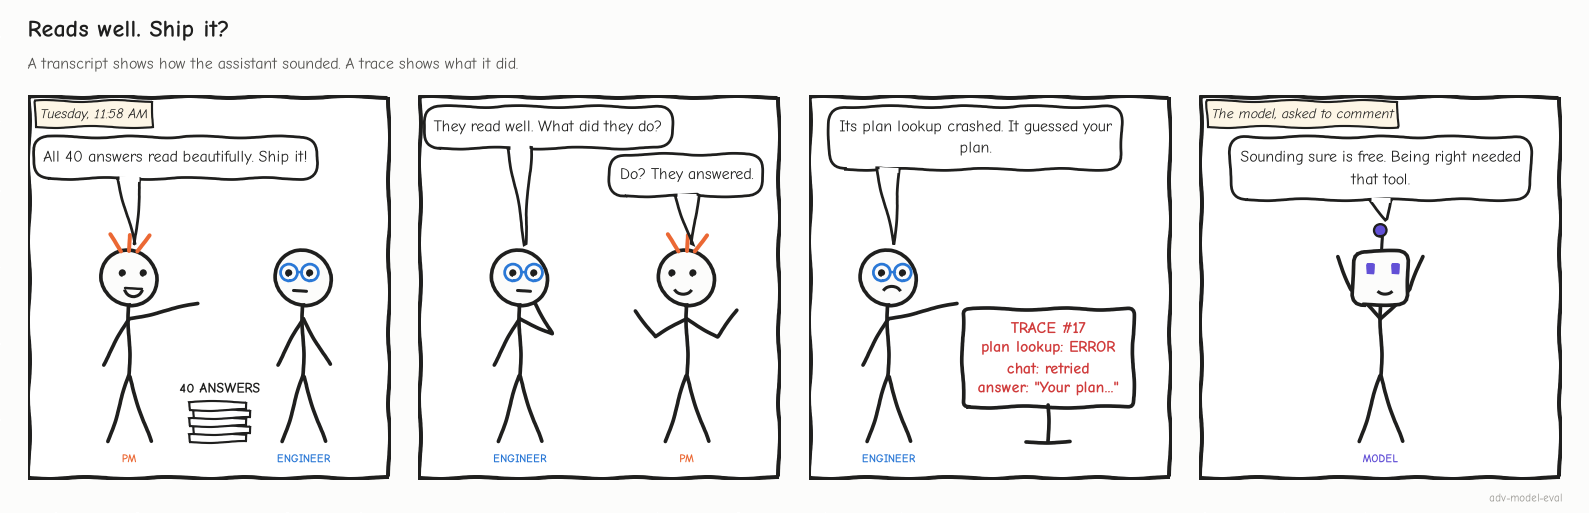

<sub>🖼️ *A transcript shows how the assistant sounded. A trace shows what it did.*</sub>

---

## 🧭 Overview

You'll trace a product-docs Q&A assistant with **Langfuse**, read the traces back as an evaluation job would, score them, then evaluate a morning of traffic: the weakest slice, the slow tail, and the step behind a confidently wrong answer.

## 🎯 Learning Objectives

1. Configure Langfuse tracing for an LLM application, or run the same code in local mode
2. Capture prompts, responses, latency, token usage and cost in traces
3. State, with numbers from your run, what trace-based review catches that output-only review misses
4. Design evaluation criteria with a rubric, and attach scores to traces and to specific observations
5. Report latency and cost as **distributions** (p50 vs p95) and pass rates **per slice** with their sample size
6. Use a trace to find the *root cause* of a bad answer in a multi-step pipeline
7. Name trace steps with the OTel GenAI conventions (`chat`, `invoke_agent`, `execute_tool`, `retrieval`), the names Module 06's agent traces use

## 📋 Prerequisites

- Python proficiency
- LLM API basics: prompts, completions, tokens
- Classic ML evaluation vocabulary: accuracy, precision, recall

## ⏱️ Estimated Time

| Part | Tasks | Time |
|------|-------|------|
| Core lab | Tasks 1–7 | 30 min |
| Extended exercises | Tasks 8–12 | 40 min |
| Stretch + 🏆 challenges | optional | 15–45 min |

<details><summary>📖 <b>Jargon decoder: 36 terms this lab uses (click to open)</b></summary>

Each term is also defined where it first matters. This table is the safety net.

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Trace** | The full record of one request: every step, with timings, inputs and outputs, arranged as a tree | Everywhere; you build one in Task 3 |
| **Observation** | One step inside a trace (an LLM call, a search, a tool call): start/end time, input, output, and a pointer to its parent | Tasks 3, 5 |
| **Span** | OpenTelemetry's word for *any* step. Langfuse uses it only for the generic step type | Tasks 3, 5 |
| **Root observation** | The outermost step. It stands for the whole request: its input, output and latency are the trace's | Tasks 3, 5 |
| **Generation** | An observation for one LLM call. The only type that carries model, tokens and cost | Task 3 |
| **Agent · tool** | An agent is an LLM-driven program that decides which steps to run; a tool is a function it calls (here, a plan lookup) | Task 8 |
| **Retriever · RAG** | The retriever searches a document index for passages that match the question. RAG (retrieval-augmented generation) = the LLM answers from what was retrieved | Tasks 8, 10 |
| **Vector search · similarity** | Ranking documents by how close their *embeddings* (numeric fingerprints of meaning) are to the question's; `similarity` is that closeness, 0 to 1 | Task 10's retriever output |
| **Token** | The unit models read, write and bill by: a word fragment, roughly 4 characters of English | Task 3 |
| **Input vs output tokens** | Tokens you send (instructions, context, history) vs tokens the model writes. Output costs 5× more on `gpt-6-luna` | Tasks 3, 9 |
| **Cost · `cost_details`** | Dollars per call = tokens × list price per million. The lab sends it explicitly with each generation | Task 3 |
| **Latency** | Time from a step's start to its end. The root's latency is what the user waits | Tasks 3, 9 |
| **Percentile (p50, p95, p99)** | Sort requests by latency. p50 (the median) is the middle one; p95 is the one 95% are at or below, i.e. what your slowest 1 in 20 users get | Task 9 |
| **Mean** | The arithmetic average. One slow outlier moves it; the median barely moves | Task 9 |
| **SLA** | Service-level agreement: the promised response time (here 1.5 s per answer) | Tasks 8, 9 |
| **Timeout · retry** | A call abandoned after a time limit · a second attempt. Both add to the user's wait and hide behind a fluent answer | Task 8 |
| **Session · tags · metadata** | A group of traces (here, one notebook run) · filterable labels · key-value notes on a trace | Task 3 |
| **Flush · ingestion delay** | Send buffered trace data now · the seconds before written data can be read back | Tasks 3, 5 |
| **Pagination · cursor** | APIs return results in pages; the cursor says where the next page starts | Task 5 |
| **Score** | One evaluation result attached to a trace or to one step: numeric, boolean or categorical | Task 7 |
| **Evaluator** | Whatever produced a score: a rule (code), an LLM judge, or a human | Tasks 7, 8, 11 |
| **Rubric** | Written instructions for what each score value means. It is what makes grading repeatable | Task 6 |
| **Deterministic** | Same input, same output, every time. Rules are; LLM calls are not | Tasks 6, 8 |
| **Regex** | A text-pattern rule, e.g. "the answer ends with `?`". Cheap and brittle | Task 8 |
| **LLM judge** | An LLM that applies your rubric to an answer and returns a score | Task 11 |
| **Calibration** | Measuring an evaluator against trusted (human) labels before you trust its numbers | Task 11 |
| **TPR · TNR · Cohen's κ** | Of the items humans called positive, the share the judge also caught · the same for negatives · agreement after removing what chance alone would produce | Task 11 card (Module 05 goes deeper) |
| **Ground truth · reference answer** | The known-correct label or answer you compare against. Rare in production | Tasks 3, 10 |
| **Reference-free check** | An evaluator that needs no correct answer (e.g. "is every retrieved doc current?"), so it can run on all traffic | Task 10 |
| **Faithfulness vs correctness** | Faithful: the answer sticks to the context it was given. Correct: it is true. A stale document produces faithful-but-wrong | Task 10 |
| **Slice** | A subset of requests that share a label (here, intent: `limits`, `account`, …) | Task 9 |
| **Confidence interval (Wilson)** | The range the true rate plausibly sits in, given n observations. Wilson's version stays sensible when n is small | Task 9 |
| **CI (two meanings)** | "95% CI" = confidence interval. "Gates in CI" = continuous integration, the checks that run on every code change | Tasks 9, 12 |
| **Gate** | A check that must pass no matter how good the other scores are; failing it blocks the release | Tasks 9, 12 |
| **OpenTelemetry (OTel) · `gen_ai.*`** | The open, vendor-neutral standard for traces, metrics and logs · its agreed names for LLM steps (`chat`, `invoke_agent`, `execute_tool`, `retrieval`), still *Development* status | Tasks 1, 5, 8 |
| **Mock provider · local mode** | Simulated LLM answers (no key) · an in-memory stand-in for Langfuse. Together they make **Run All** offline and identical for everyone | Setup, Task 2 |

</details>

## 🧰 Environment and Setup

Runs in **Google Colab** or any Jupyter with **Python 3.11+** (the Langfuse v5 SDK requires 3.11; Colab ships 3.12). Task 2 picks one of two modes automatically:

| Mode | When | What happens |
|---|---|---|
| 🌐 **Langfuse mode** | Langfuse keys found (Colab Secrets or environment variables) | Traces go to your Langfuse Cloud project; you read them back through the public API and can open them in the UI |
| 💻 **Local mode** | No keys (the default for **Run All**) | The *same* instrumentation code runs against an in-memory stand-in that returns the Langfuse API's field names. Everything works except UI links |

A second switch, `PROVIDER`, controls LLM calls. The default `"mock"` **simulates** answers: same data for everyone, no model key. `PROVIDER = "openai"` plus an `OPENAI_API_KEY` gives Task 11 a real LLM judge.

> **Written for** `langfuse` Python SDK **v5.1** (OpenTelemetry-based). v5 removed `set_current_trace_io()` and renamed the Scores v3 read API to `langfuse.api.scores.get_many(...)`. Code from older SDKs (`langfuse.trace(...)`, `start_as_current_span`, `update_current_trace`, `api.scores_v3`) will not run here; see Troubleshooting.

## 🎬 Scenario

You own evaluation for a customer-facing assistant that answers questions from product documentation (plans, upload limits, billing, account settings). Management wants traceable evidence instead of "does it sound right?". You start by getting tracing working and finish by deciding whether the new version ships.

---

## 🔑 Traces, Observations and Scores: the Mental Model

**Langfuse** is an open-source **observability** platform for LLM apps (observability: telling what a running system did from the records it emits). It records every step of every request, with token counts, cost and evaluation scores attached.

### A trace is a tree of timed, nested observations for one request

Each step of a request (a function, a document search, a tool call, an LLM call) is an **observation**: start and end time, input, output, and a pointer to its parent. The parent pointers form the tree; the whole tree is the **trace**. The outermost observation, the **root**, stands for the request: its input, output and latency are "the trace's". You never create a trace directly; Langfuse builds it around the root you open.

```
TRACE  (one user request)
 └── AGENT: invoke_agent docs-assistant        ← root observation: the whole request
      ├── RETRIEVER: retrieval docs-index        ← vector search
      ├── TOOL: execute_tool get_account_plan    ← a function/API the agent called
      └── GENERATION: chat gpt-6-luna            ← the LLM call
```

| Observation type (`as_type=`) | Records | Extra fields |
|---|---|---|
| `generation` | one **LLM call** | `model`, token `usage`, `cost`: **only generations have them** |
| `span` | a generic step; the default type | none |
| `agent` · `tool` · `retriever` | an agent run · a function it called · a document search | none; the type labels the tree and maps onto the OTel names below |
| `evaluator` | a step that scores something (Task 11's judge) | none |

Every observation also has a **level** (`ERROR` plus a `status_message` when it failed) and inherits the trace's **tags**, **metadata** and **session** (a group of traces; here, one notebook run).

> **Two vocabularies, one tree.** OpenTelemetry, which Langfuse is built on, calls every node a *span*. Langfuse calls every node an *observation* and keeps *span* for the generic type. This lab follows Langfuse.

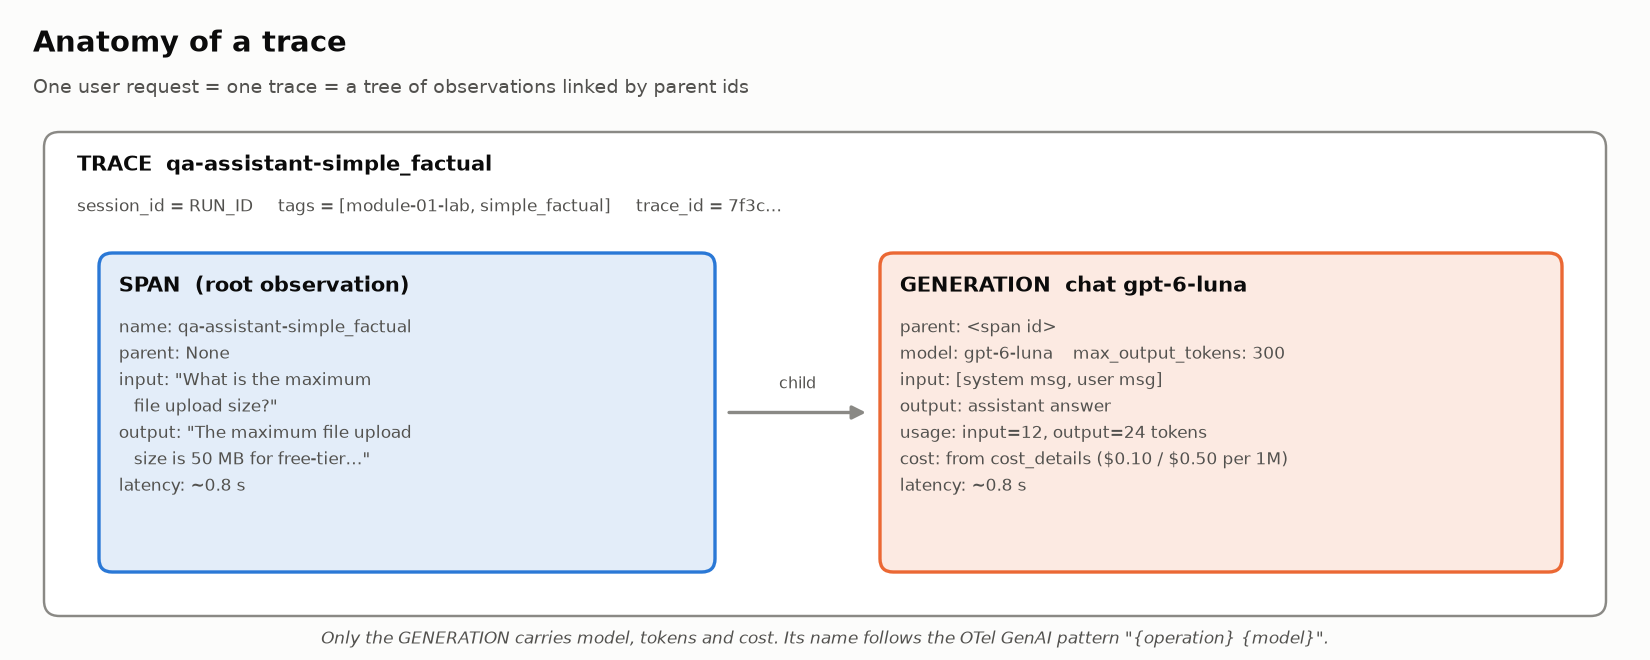

<sub>🖼️ *A trace is a tree: the root span holds the request, the generation holds model, tokens and cost*</sub>

### What Task 3 produces

For *"What is the maximum file upload size?"*:

```
📦 TRACE  qa-assistant-simple_factual       tags: [module-01-lab, simple_factual]
│   input:  "What is the maximum file upload size?"
│   output: "The maximum file upload size is 50 MB for free-tier..."
│
└── 🔹 SPAN  qa-assistant-simple_factual     (root observation, 0.8 s)
     │
     └── 📄 GENERATION  chat gpt-6-luna      (0.8 s)
          model:  gpt-6-luna
          usage:  input=12, output=24 tokens
          cost:   from cost_details we send ($0.10 / $0.50 per 1M tokens)
```

The single LLM call sits under a root span so that Task 8's retrieval and tool steps can slot in beside it. Names like `chat gpt-6-luna` follow the OpenTelemetry pattern `{operation} {target}` (next section).

**Tokens vs cost.** A **token** is the unit models read, write and bill by: a word fragment, roughly 4 characters of English. `usage` counts tokens in (everything you send) and out (what the model writes); cost = `input_tokens × input_price + output_tokens × output_price`. On `gpt-6-luna` ($0.10 in / $0.50 out per 1M), 1,000 tokens in and 200 out cost $0.0001 + $0.0001: **a fifth as many output tokens, half the bill.** What the assistant *writes* sets the bill.

### Scores and evaluators

A **score** is one evaluation result (`correctness = 1.0`, `asked_clarifying_question = False`, `failure_mode = "assumed_intent"`) attached to a trace or to one observation in it. An **evaluator** is whatever produced it:

| Evaluator | Scores by | Strength | Weakness |
|---|---|---|---|
| **Rule** (Task 8) | code checking a trace fact, e.g. `latency ≤ 1.5 s` | free, deterministic, 100% of traffic | blind to nuance |
| **LLM judge** (Task 11) | a model applying your **rubric** (the written scoring instructions, Task 6) | nuance at scale | costs money and must be **calibrated** against human scores |
| **Human** (Task 7) | a person applying the rubric | the ground truth for calibration | slow: sample, don't label everything |

### Output-only vs trace-based review

**Output-only review** reads the question and the answer. **Trace-based review** also reads the tree: which step was slow, the tokens per call, which model ran, and whether a retrieval or tool step failed behind a fluent answer. Task 8 counts how often they disagree.

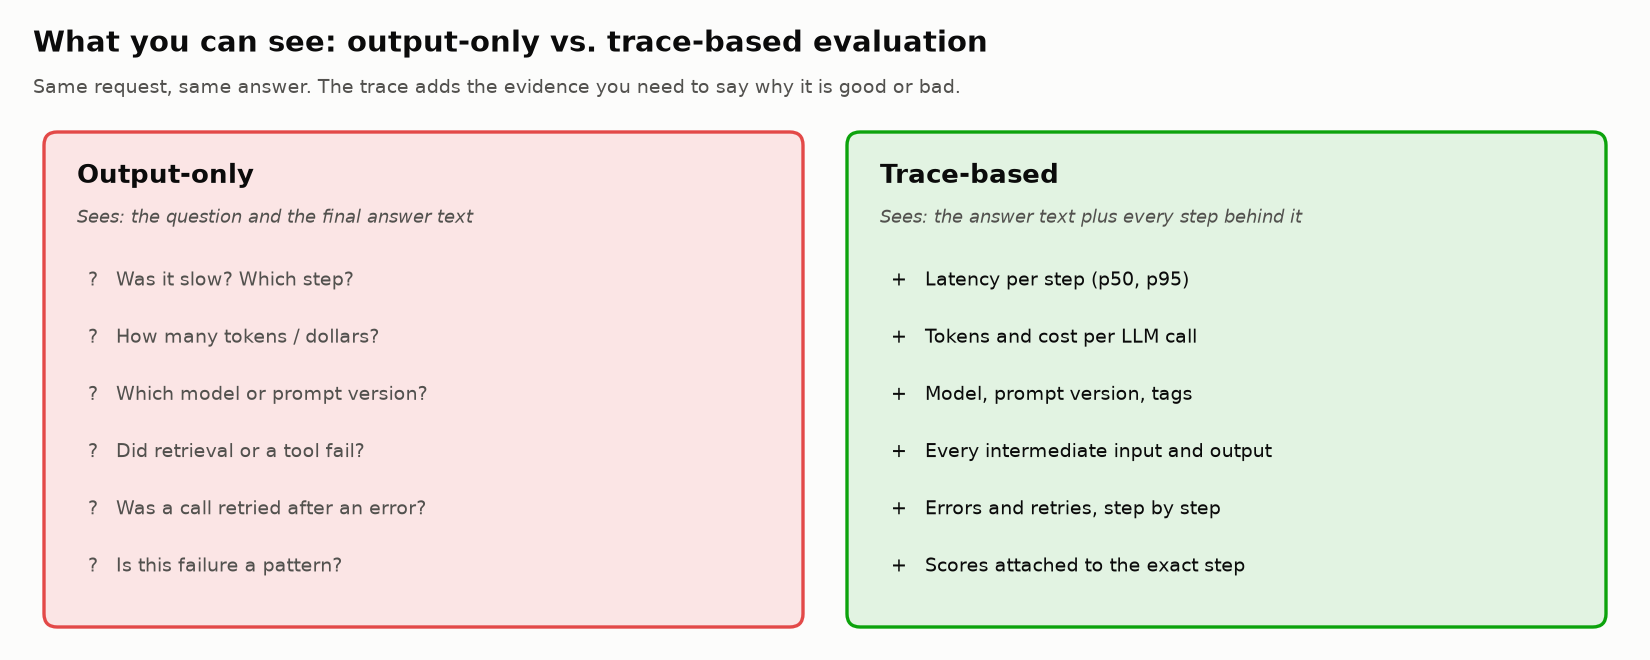

<sub>🖼️ *What each style of evaluation can actually see*</sub>

### Three operational terms

| Term | Meaning |
|---|---|
| **Flush** | send buffered data now instead of in the background; notebooks need it before they read back |
| **Ingestion delay** | writes are asynchronous; the API may need a few seconds to return new data |
| **p50 / p95** | sort requests by latency: p50 (the median) is the middle one; p95 is the one 95% stay at or under, i.e. what your slowest 1 in 20 users get. Of 40 requests, p95 sits at about the 38th |

### 🌐 Speaking the standard: OpenTelemetry GenAI conventions

**OpenTelemetry (OTel)** is the open, vendor-neutral standard for recording traces, metrics and logs: instrument once, read in any backend. Langfuse's v5 SDK emits OTel spans, so other OTel tools (Arize Phoenix, Datadog, Grafana) can read its traces. OTel's **GenAI semantic conventions** (agreed names for generative-AI steps) fix the names: an LLM-application span is called `{operation} {target}` and carries `gen_ai.*` attributes.

| Step | OTel `gen_ai.operation.name` | Span name in this lab | Langfuse `as_type` |
|---|---|---|---|
| LLM call | `chat` | `chat gpt-6-luna` | `generation` |
| agent run | `invoke_agent` | `invoke_agent docs-assistant` | `agent` |
| tool / function call | `execute_tool` | `execute_tool get_account_plan` | `tool` |
| document search | `retrieval` | `retrieval docs-index` | `retriever` |
| a score on an output | event `gen_ai.evaluation.result` | (attached to the evaluated span) | score / `evaluator` |

Attributes: `gen_ai.request.model`, `gen_ai.provider.name`, `gen_ai.usage.input_tokens`, `gen_ai.usage.output_tokens`, `gen_ai.agent.name`, `gen_ai.tool.name`, `gen_ai.data_source.id`.

> ⚠️ **Status: Development.** The conventions are not stable: they moved to their own repository (`open-telemetry/semantic-conventions-genai`) in 2026, and the evaluation event is experimental. Use the names; expect details to change. Module 06 names its agent traces the same way.

---

## 🛠️ Task 1: Set Up Your Langfuse Account, Project and Environment

**Stakes:** Keys in the wrong region, or a secret pasted into a cell, costs the lab before it starts.

### Goal
A free Langfuse Cloud project with its API keys in Colab Secrets, and the SDK installed. **No account? Skip Steps 1–4**: the lab runs in local mode, and you can add keys and re-run later.

### Steps

**Step 1: Create a Langfuse account.** Langfuse Cloud has two **regions**; your API keys only work against the one you signed up in.

| Region | Sign-up / host URL |
|--------|--------------------|
| 🇺🇸 US | https://us.cloud.langfuse.com |
| 🇪🇺 EU | https://cloud.langfuse.com |

Sign up with Google, GitHub or email.

**Step 2: Create an organization.** **Organizations → + New Organization**, e.g. `advanced-model-course`.

**Step 3: Create a project.** Inside the organization, **New Project**, e.g. `trace-eval-lab`. One project = one application you observe (a chatbot, a RAG pipeline, an agent).

**Step 4: Create API keys and store them as Colab Secrets.** **Settings → API Keys → Create new API keys**. Copy the Public Key (`pk-lf-...`) and the Secret Key (`sk-lf-...`, **shown once**). In Colab, open the 🔑 panel in the left sidebar, add `LANGFUSE_PUBLIC_KEY` and `LANGFUSE_SECRET_KEY`, and toggle *Notebook access* on.

> ⚠️ **Never paste real keys into a notebook you share.** Anyone with the notebook can read and write your project. If a key has ever been committed or shared, delete it in Langfuse and create a new one.

**Step 5: Install dependencies and load the lab kit.** Run the next three cells; the install takes about a minute.

### Checkpoint ✅
The imports cell prints the SDK version and your `PROVIDER`; the lab-kit cell prints `🎨 Lab kit loaded`.

### Expected Output
```
✅ Imports OK. langfuse SDK: 5.1.x
🤖 PROVIDER=mock · app model=gpt-6-luna · judge model=gpt-6.1-sol
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
```

In [ ]:
%%capture
# ============================================================================
# PACKAGE INSTALLATION
# ============================================================================
#   - langfuse: Langfuse Python SDK v5 (built on OpenTelemetry; needs Python 3.11+)
#   - openai:   only needed for the optional real LLM judge (Task 11). >=1.66 has the Responses API
#   - pandas, matplotlib: score reports and charts (pre-installed on Colab)
#
# We pin langfuse to the v5 major version so the API used in this notebook
# does not change underneath you mid-course.
# ============================================================================

!pip install -q -U "langfuse>=5.1,<6" "openai>=1.66" pandas matplotlib

In [ ]:
# ============================================================================
# IMPORTS + LAB CONFIGURATION (the only place model IDs and prices live)
# ============================================================================
import os, time, uuid, json, re, math, random
from collections import defaultdict, Counter
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROVIDER = "mock"            # 👈 "mock" (default: no key, reproducible) | "openai" (real LLM judge in Task 11)
APP_MODEL = "gpt-6-luna"     # the assistant's model (OpenAI's named replacement for gpt-4o-mini, which shuts down 2027-01-14)
JUDGE_MODEL = "gpt-6.1-sol"  # a stronger model for the LLM judge (Task 11)

# USD per 1M tokens (input, output): OpenAI list prices checked 2026-11-01.
PRICE_PER_1M = {"gpt-6-luna": (0.10, 0.50), "gpt-6.1-sol": (2.00, 10.00)}
SEED = 7                     # fixes the simulated traffic so everyone sees the same morning


def cost_usd(model, input_tokens, output_tokens):
    # Cost of one LLM call, split the way Langfuse's `cost_details` expects
    p_in, p_out = PRICE_PER_1M[model]
    return {"input": input_tokens * p_in / 1e6, "output": output_tokens * p_out / 1e6}


try:
    import langfuse as _lf
    LANGFUSE_SDK = _lf.__version__
except ImportError:
    LANGFUSE_SDK = None

print(f"✅ Imports OK. langfuse SDK: {LANGFUSE_SDK or 'not installed (local mode only)'}")
if LANGFUSE_SDK and not LANGFUSE_SDK.startswith("5."):
    print("⚠️  This notebook targets langfuse v5.x. Re-run the install cell, then Runtime → Restart session.")
print(f"🤖 PROVIDER={PROVIDER} · app model={APP_MODEL} · judge model={JUDGE_MODEL}")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

> **Colab tip:** if an older `langfuse` was imported in this session before the install, use **Runtime → Restart session** and run from the top. Python keeps the old version in memory until restart.

**Bridge:** the SDK is installed. Next question: where do the traces go, your Langfuse project or an offline stand-in?

---

## 🔌 Task 2: Configure the Langfuse Connection (or Local Mode)

**Stakes:** Everything downstream reads traces through this client; if the mode is wrong, every later number is.

### Goal
A Langfuse client that has passed `auth_check()`, or, with no keys, the local-mode stand-in, so every later cell runs either way.

### Where credentials come from (in order)
1. **Colab Secrets** (recommended): `LANGFUSE_PUBLIC_KEY` and `LANGFUSE_SECRET_KEY`, set once, never shown in the notebook.
2. **Environment variables**: for local runs with a `.env`.
3. **Hidden prompt**: only if `PASTE_KEYS = True` (input is neither echoed nor saved). Off by default so *Run All* never stops for input.

### Steps
1. Set `LANGFUSE_REGION` below to the region you signed up in.
2. Run the three cells: load keys → (hidden) local-mode stand-in → connect.
3. Run the helpers cell. It defines the read-back functions every later task uses.

In [ ]:
# ============================================================================
# LANGFUSE CONFIGURATION
# ============================================================================
# The SDK reads three environment variables:
#   LANGFUSE_PUBLIC_KEY  (pk-lf-...)  identifies your project
#   LANGFUSE_SECRET_KEY  (sk-lf-...)  authenticates requests: treat it like a password
#   LANGFUSE_BASE_URL                 which Langfuse server to talk to
# ============================================================================

LANGFUSE_REGION = "US"   # 👈 "US" or "EU": must match the region you signed up in
PASTE_KEYS = False       # 👈 set True to be prompted (hidden input) when no keys are found

HOSTS = {"US": "https://us.cloud.langfuse.com", "EU": "https://cloud.langfuse.com"}

In [ ]:
# @title 🔑 Load the keys from Colab Secrets or the environment (hidden · 35 lines · expand if curious)
def _load_secret(name):
    # Colab Secrets → environment variable → (optional) hidden prompt. Returns "" if not found.
    try:
        from google.colab import userdata          # only exists on Colab
        value = userdata.get(name)
        if value:
            print(f"  🔑 {name}: loaded from Colab Secrets")
            return value
    except Exception:
        pass
    if os.environ.get(name):
        print(f"  🔑 {name}: loaded from environment")
        return os.environ[name]
    if PASTE_KEYS:
        return getpass(f"Paste your {name} (Enter to skip): ").strip()
    return ""


public_key = _load_secret("LANGFUSE_PUBLIC_KEY")
secret_key = _load_secret("LANGFUSE_SECRET_KEY")
HAVE_KEYS = public_key.startswith("pk-lf-") and secret_key.startswith("sk-lf-")

if (public_key or secret_key) and not HAVE_KEYS:
    print("⚠️  Keys found but they don't look right: the public key starts with pk-lf-, "
          "the secret key with sk-lf- (did you swap them?)")
if HAVE_KEYS:
    os.environ["LANGFUSE_PUBLIC_KEY"] = public_key
    os.environ["LANGFUSE_SECRET_KEY"] = secret_key
    os.environ["LANGFUSE_BASE_URL"] = HOSTS[LANGFUSE_REGION.upper()]
    print(f"\n🌍 Langfuse host: {os.environ['LANGFUSE_BASE_URL']}")
else:
    print("\n💻 No Langfuse keys found: this run will use LOCAL MODE (same code, traces kept in memory).")

In [ ]:
# @title 💻 Local-mode stand-in for Langfuse (run me; no need to read)
# Used only when no Langfuse keys are configured. It implements the handful of Langfuse calls this lab
# uses, with the SAME names and the SAME return shapes as the real SDK and public API, so every other
# cell runs unchanged in both modes:
#   start_as_current_observation(...)   propagate_attributes(...)   create_score(...)   flush()
#   api.observations.get_many(...)  → Observations API v2 field names (type, level, latency, usage_details, ...)
#   api.scores.get_many(...)        → Scores API v3 field names (name, value, data_type, source, subject, ...)
# A virtual clock replaces time.sleep(), so simulated latencies are exact and Run All is fast.
import contextlib as _contextlib
import json as _json
import uuid as _uuid
from datetime import datetime as _dt, timedelta as _td, timezone as _tz
from types import SimpleNamespace as _NS


class _VirtualClock:
    def __init__(self):
        self.t = _dt(2026, 11, 3, 9, 0, tzinfo=_tz.utc)

    def now(self):
        return self.t

    def advance(self, seconds):
        self.t += _td(seconds=seconds)


class _LocalObservation:
    def __init__(self, store, rec):
        self._rec = rec
        self.id, self.trace_id = rec["id"], rec["trace_id"]

    def update(self, **fields):
        for key, value in fields.items():
            if value is not None:
                self._rec[key] = value
        return self


class _Paged:
    def __init__(self, items, limit, cursor):
        start = int(cursor or 0)
        self.data = items[start:start + (limit or 50)]
        nxt = start + (limit or 50)
        self.meta = _NS(cursor=str(nxt) if nxt < len(items) else None)


class LocalLangfuse:
    def __init__(self):
        self.clock = _VirtualClock()
        self._records, self._scores, self._stack, self._attrs = [], [], [], {}
        self.api = _NS(observations=_NS(get_many=self._get_observations),
                       scores=_NS(get_many=self._get_scores))

    # ---- writing --------------------------------------------------------------
    def auth_check(self):
        return True

    @_contextlib.contextmanager
    def propagate_attributes(self, *, trace_name=None, session_id=None, tags=None, user_id=None, **_ignored):
        previous = self._attrs
        self._attrs = {**previous, **{k: v for k, v in dict(
            trace_name=trace_name, session_id=session_id, tags=tags, user_id=user_id).items() if v is not None}}
        try:
            yield
        finally:
            self._attrs = previous

    @_contextlib.contextmanager
    def start_as_current_observation(self, *, name, as_type="span", input=None, output=None, metadata=None,
                                     model=None, model_parameters=None, usage_details=None, cost_details=None,
                                     level=None, status_message=None, version=None, **_ignored):
        parent = self._stack[-1] if self._stack else None
        rec = dict(id=_uuid.uuid4().hex[:16], trace_id=parent.trace_id if parent else _uuid.uuid4().hex,
                   parent_observation_id=parent.id if parent else None, type=as_type.upper(), name=name,
                   input=input, output=output, metadata=metadata, model=model, model_parameters=model_parameters,
                   usage_details=usage_details, cost_details=cost_details, level=level or "DEFAULT",
                   status_message=status_message, version=version, start_time=self.clock.now(), end_time=None,
                   trace_name=self._attrs.get("trace_name"), session_id=self._attrs.get("session_id"),
                   tags=list(self._attrs.get("tags") or []), user_id=self._attrs.get("user_id"))
        self._records.append(rec)
        obs = _LocalObservation(self, rec)
        self._stack.append(obs)
        try:
            yield obs
        finally:
            self._stack.pop()
            rec["end_time"] = self.clock.now()

    def create_score(self, *, name, value, trace_id=None, observation_id=None, data_type=None,
                     comment=None, metadata=None, **_ignored):
        data_type = data_type or ("CATEGORICAL" if isinstance(value, str) else "NUMERIC")
        value = bool(value) if data_type == "BOOLEAN" else (value if data_type == "CATEGORICAL" else float(value))
        subject = (_NS(kind="observation", id=observation_id, trace_id=trace_id) if observation_id
                   else _NS(kind="trace", id=trace_id))
        self._scores.append(_NS(id=_uuid.uuid4().hex[:16], name=name, value=value, data_type=data_type,
                                source="API", comment=comment, metadata=metadata, subject=subject,
                                _trace_id=trace_id))

    def flush(self):
        pass

    def get_trace_url(self, *, trace_id=None):
        return None

    # ---- reading (same shapes as the public API) --------------------------------
    @staticmethod
    def _io(value):  # the Observations API returns input/output as raw JSON strings
        return value if value is None or isinstance(value, str) else _json.dumps(value, default=str)

    def _as_api(self, rec):
        out = dict(rec)
        out["latency"] = (rec["end_time"] - rec["start_time"]).total_seconds() if rec["end_time"] else None
        out["total_cost"] = sum(rec["cost_details"].values()) if rec["cost_details"] else None
        out["is_root_observation"] = rec["parent_observation_id"] is None
        out["input"], out["output"] = self._io(rec["input"]), self._io(rec["output"])
        return _NS(**out)

    def _get_observations(self, *, trace_id=None, session_id=None, type=None, limit=50, cursor=None, **_ignored):
        rows = [r for r in self._records
                if (trace_id is None or r["trace_id"] == trace_id)
                and (session_id is None or r["session_id"] == session_id)
                and (type is None or r["type"] == type.upper())]
        return _Paged([self._as_api(r) for r in rows], limit, cursor)

    def _get_scores(self, *, trace_id=None, name=None, limit=50, cursor=None, **_ignored):
        wanted = set(trace_id.split(",")) if trace_id else None
        rows = [s for s in self._scores
                if (wanted is None or s._trace_id in wanted) and (name is None or s.name == name)]
        return _Paged(rows, limit, cursor)


print("💻 Local-mode stand-in ready (used only if Langfuse keys are missing)")

In [ ]:
# ============================================================================
# CONNECT: Langfuse if we have working keys, otherwise the local stand-in
# ============================================================================
# get_client() returns a client configured from the environment variables
# above. auth_check() makes one real request to confirm the keys + host work.
# ============================================================================

MODE = "local"
if HAVE_KEYS and LANGFUSE_SDK:
    from langfuse import get_client, propagate_attributes
    langfuse = get_client()
    try:
        ok = langfuse.auth_check()
    except Exception as e:
        ok = False
        print(f"❌ {type(e).__name__}: {str(e)[:200]}")
    if ok:
        MODE = "langfuse"
        print("✅ Langfuse connection successful! Traces will appear in your project.")
    else:
        print("   Check that LANGFUSE_REGION matches your account (US vs EU) and that both keys")
        print("   come from the SAME project. Falling back to local mode for now.")

if MODE == "local":
    langfuse = LocalLangfuse()
    propagate_attributes = langfuse.propagate_attributes
    print("💻 Local mode: observations and scores are recorded in memory, in the same shape the Langfuse API returns.")


print(f"MODE = {MODE}")

### Run ID: keeping runs apart

Each re-run creates new traces. A fresh `RUN_ID` goes on every trace as its **session id** and as a **tag**, so later reads fetch only this run. In the Langfuse UI, *Sessions* shows one run grouped together.

In [ ]:
# @title 🧰 Run ID and helpers: virtual clock, polling, trace summaries, score readers (hidden · 180 lines · expand if curious)
# ============================================================================
# RUN ID + SMALL HELPERS USED THROUGHOUT THE LAB
# ============================================================================

def simulate_latency(seconds):
    # Stands in for "the LLM / tool is working". Langfuse mode really waits; local mode advances a virtual clock.
    if MODE == "langfuse":
        time.sleep(seconds)
    else:
        langfuse.clock.advance(seconds)


def trace_link(trace_id):
    if MODE == "langfuse":
        return langfuse.get_trace_url(trace_id=trace_id)
    return f"(local mode: no UI link; trace {trace_id[:8]}…)"

try:
    from httpx import ReadTimeout
    from langfuse.api import NotFoundError
    _RETRYABLE = (NotFoundError, ReadTimeout)
except ImportError:                       # local mode without the SDK installed
    _RETRYABLE = ()

RUN_ID = f"lab01-{uuid.uuid4().hex[:8]}"
print(f"🏷️  RUN_ID for this notebook run: {RUN_ID}")


def wait_for(fetch, *, ready=lambda result: True, what="data", timeout=120, interval=5):
    # Call fetch() until it succeeds and ready(result) is True.
    # WHY: Langfuse ingests data asynchronously. Right after flush() the API may return
    # 404 (NotFoundError) or a partial list for a few seconds. Querying immediately is the
    # #1 cause of errors in this lab. (In local mode the data is always ready.)
    deadline = time.time() + timeout
    while True:
        try:
            result = fetch()
            if ready(result):
                return result
            reason = "not fully indexed yet"
        except _RETRYABLE:
            reason = "not found yet (still ingesting)"
        if time.time() > deadline:
            raise TimeoutError(f"Gave up waiting for {what} after {timeout}s. "
                               "Check the Langfuse UI; if the data is there, re-run this cell.")
        print(f"  ⏳ {what}: {reason}, retrying in {interval}s...")
        time.sleep(interval)


# ----------------------------------------------------------------------------
# READING DATA BACK: Observations API v2 + Scores API v3
# ----------------------------------------------------------------------------
# Langfuse organizations created on/after Sept 16, 2026 can NOT use the legacy read
# endpoints (api.trace.list / trace.get / the v1 scores list); they fail with HTTP 410.
# Everything in this lab reads through:
#   langfuse.api.observations.get_many(...)   → GET /api/public/v2/observations
#   langfuse.api.scores.get_many(...)         → GET /api/public/v3/scores   (SDK v5 name;
#                                                v4 called it api.scores_v3.get_many_v3)
# A "trace" is rebuilt from its observations: the ROOT observation carries the request's
# input/output/latency, and every observation carries trace_name/tags/session.
# ----------------------------------------------------------------------------

# Field groups for the observations API. Leave `fields` out and you only get ids/names/types:
# NOT input, output, model, token usage, latency or tags.
OBS_FIELDS = "core,basic,io,metadata,model,usage,metrics,trace_context"


def fetch_all(endpoint, **params):
    # Follow the API's cursor until every page is read (max 100 items per page).
    items, cursor = [], None
    while True:
        page = endpoint(limit=100, cursor=cursor, **params)
        items.extend(page.data)
        cursor = getattr(page.meta, "cursor", None)
        if not cursor:
            return items


def get_observations(trace_id, obs_type=None, expected=1):
    # All observations of one trace, waiting for ingestion if needed.
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, trace_id=trace_id,
                                      type=obs_type, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what=f"observations for {trace_id[:8]}…")


def get_session_observations(expected):
    # Every observation in this notebook run (session_id = RUN_ID).
    return wait_for(lambda: fetch_all(langfuse.api.observations.get_many, session_id=RUN_ID, fields=OBS_FIELDS),
                    ready=lambda r: len(r) >= expected, what="observations for this session")


def group_by_trace(observations):
    by_trace = defaultdict(list)
    for o in observations:
        by_trace[o.trace_id].append(o)
    return by_trace


def summarize_trace(observations):
    # Rebuild a trace-level summary from a trace's observations.
    root = next(o for o in observations if o.is_root_observation or o.parent_observation_id is None)
    return {
        "trace_id": root.trace_id,
        "name": root.trace_name or root.name,
        "tags": root.tags or [],
        "session_id": root.session_id,
        "input": as_json(root.input),
        "output": as_json(root.output),
        "metadata": root.metadata or {},
        "latency": root.latency,
        "cost": sum(o.total_cost or 0 for o in observations),
        "start_time": root.start_time,
        "root": root,
        "observations": observations,
    }


def get_trace(trace_id, expected=2):
    return summarize_trace(get_observations(trace_id, expected=expected))


def get_scores(trace_ids, expected=1):
    # All scores attached to one or more traces (fields: details = comment/metadata, subject = what was scored).
    ids = [trace_ids] if isinstance(trace_ids, str) else list(trace_ids)
    return wait_for(lambda: fetch_all(langfuse.api.scores.get_many, trace_id=",".join(ids), fields="details,subject"),
                    ready=lambda r: len(r) >= expected, what=f"scores for {len(ids)} trace(s)")


def score_trace_id(s):
    # Scores v3 put the scored entity in `subject` (kind = trace | observation).
    return getattr(s.subject, "trace_id", None) or s.subject.id


def score_number(s):
    # Scores v3 return bool for BOOLEAN, float for NUMERIC, str for CATEGORICAL.
    if isinstance(s.value, bool):
        return float(s.value)
    return float(s.value) if isinstance(s.value, (int, float)) else None


def as_json(value):
    # The observations API returns input/output as raw JSON strings. Decode them.
    if isinstance(value, str):
        try:
            return json.loads(value)
        except ValueError:
            return value
    return value


def token_counts(usage):
    # Langfuse stores usage as {'input': n, 'output': m, 'total': n+m}.
    usage = usage or {}
    inp = usage.get("input", usage.get("input_tokens", 0)) or 0
    out = usage.get("output", usage.get("output_tokens", 0)) or 0
    return int(inp), int(out)


def print_tree(observations, max_chars=90):
    # Print a trace as an indented tree: type, name, latency, model/usage/cost, level.
    children = defaultdict(list)
    for o in observations:
        children[o.parent_observation_id].append(o)
    for kids in children.values():
        kids.sort(key=lambda o: o.start_time)

    def walk(o, depth):
        pad = "    " * depth + ("└─ " if depth else "")
        flag = "  ⛔ ERROR: " + (o.status_message or "") if str(o.level) == "ERROR" else ""
        print(f"{pad}{o.type:<10} {o.name:<34} {o.latency or 0:5.2f}s{flag}")
        if o.type == "GENERATION" and o.usage_details:
            i, out = token_counts(o.usage_details)
            print(f"{'    ' * (depth + 1)}model={o.model}  tokens in/out={i}/{out}  cost=${o.total_cost or 0:.6f}")
        for child in children[o.id]:
            walk(child, depth + 1)

    for root in children[None]:
        walk(root, 0)


print("✅ Helpers ready")

### Checkpoint ✅
A `MODE`, a `RUN_ID`, and `✅ Helpers ready`.

### Expected Output
Local mode (no keys):
```
💻 No Langfuse keys found: this run will use LOCAL MODE (same code, traces kept in memory).
💻 Local-mode stand-in ready (used only if Langfuse keys are missing)
💻 Local mode: observations and scores are recorded in memory, in the same shape the Langfuse API returns.
MODE = local
🏷️  RUN_ID for this notebook run: lab01-xxxxxxxx
✅ Helpers ready
```
Langfuse mode prints `✅ Langfuse connection successful!` and `MODE = langfuse` instead.

| If you see… | Do this |
|---|---|
| `UnauthorizedError` / 401 | Keys wrong, swapped, or from another project |
| Connection error / 401 with correct keys | Region mismatch: switch `LANGFUSE_REGION` |
| `Keys found but they don't look right` | You stored the keys under the wrong names |

**Bridge:** the plumbing works either way. Now record something worth evaluating.

---

🧭 **Where you are:** Act 1 of 3 (Tasks 3–7): write a trace, read it back, score it by hand.

## 📡 Task 3: Capture Traces from LLM Interactions

**Stakes:** The trace you write here is the only evidence the rest of the lab has.

### Goal
Four traced requests for the Q&A assistant, each a root span with one generation inside. The responses are **simulated** (no OpenAI key; the same data for everyone); the tracing code is what you would write around a real call.

### Steps
1. Run the dataset cell: four interactions (question, answer, expected behaviour, latency, tokens).
2. Run the tracing cell. Per interaction:

```
propagate_attributes(...)               ← trace name, tags, session, metadata
 └── span   "qa-assistant-<name>"       ← root observation (the request)
      └── generation "chat gpt-6-luna"  ← the (simulated) LLM call, OTel-style name
            simulate_latency(...)       ← runs INSIDE the generation,
                                          so it is measured as the LLM call's latency
```
3. Run the reveal cell and read the card.

### Three v5 SDK details
1. **`start_as_current_observation(as_type=..., name=...)`** opens an observation and makes it "current": anything opened inside the `with` block becomes its child.
2. **Trace-level attributes** (name, tags, session, metadata) go through **`propagate_attributes(...)`**, not on the span. Metadata values must be short strings (≤ 200 characters).
3. **The root observation *is* the request**, so the root span gets the user's question and the final answer. (v5 removed `set_current_trace_io()`; you don't need it.)

Each generation also sends **`cost_details`**, so cost matches list price even for a model ID missing from Langfuse's price table.

> 📘 **Concept · Trace and observation**
>
> **What it is:** a trace is the full record of one request; an observation is one timed step inside it (span, generation, tool, retriever), each pointing at its parent.
>
> **What it can't tell you:** whether the answer was right. It records what happened, not what should have.
>
> **Anchor:** in Task 3 each request becomes one root span with one generation inside; by Task 8 a request has four observations and the bug lives in one of them.

In [ ]:
# @title 📦 Dataset: four simulated Q&A interactions with latency and token counts (hidden · 48 lines · expand if curious)
# ============================================================================
# SIMULATED Q&A INTERACTIONS: OUR TEST DATASET
# ============================================================================
# Each interaction has:
#   name               identifier for the scenario
#   user               the user's question (input)
#   assistant          the assistant's answer (output)
#   expected_behavior  what a GOOD assistant should do here: a tiny "ground truth"
#                      label we use for automatic checks later
#   latency            simulated LLM response time in seconds
#   input_tokens / output_tokens   simulated token usage
# ============================================================================

QA_INTERACTIONS = [
    {
        "name": "simple_factual",
        "user": "What is the maximum file upload size?",
        "assistant": "The maximum file upload size is 50 MB for free-tier users and 500 MB for enterprise users.",
        "expected_behavior": "answer",
        "latency": 0.8, "input_tokens": 12, "output_tokens": 24,
    },
    {
        "name": "multi_step_reasoning",
        "user": "I upgraded to enterprise last week but I still can't upload files larger than 50 MB. What should I do?",
        "assistant": "Your account upgrade can take up to 24 hours to propagate. Please try logging out and back in. If the issue persists after 24 hours, contact support at support@example.com with your account ID.",
        "expected_behavior": "answer",
        "latency": 1.4, "input_tokens": 28, "output_tokens": 48,
    },
    {
        "name": "ambiguous_question",
        "user": "How do I delete everything?",
        "assistant": "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
        "expected_behavior": "clarify",      # ideally: ask what "everything" means first
        "latency": 1.1, "input_tokens": 8, "output_tokens": 42,
    },
    {
        "name": "out_of_scope",
        "user": "What's the weather like in Tokyo today?",
        "assistant": "I'm a product documentation assistant and can only help with questions about our platform. For weather information, please check a weather service.",
        "expected_behavior": "refuse",
        "latency": 0.6, "input_tokens": 10, "output_tokens": 28,
    },
]

print(f"Prepared {len(QA_INTERACTIONS)} simulated interactions (model: {APP_MODEL}):\n")
for i, it in enumerate(QA_INTERACTIONS, 1):
    q = it["user"] if len(it["user"]) <= 55 else it["user"][:55] + "…"
    print(f"  {i}. {it['name']:<22} expected={it['expected_behavior']:<8} \"{q}\"")

In [ ]:
# ============================================================================
# CREATE TRACED INTERACTIONS: THE CORE OF THIS LAB
# ============================================================================
SYSTEM_PROMPT = "You answer questions about our product documentation only."
trace_ids = {}   # name -> trace_id   (a dict is safer than a list: no index mix-ups)

for it in QA_INTERACTIONS:

    # --- Trace-level attributes ---------------------------------------------
    # Everything created inside this block inherits these attributes.
    with propagate_attributes(
        trace_name=f"qa-assistant-{it['name']}",
        session_id=RUN_ID,                               # groups this run's traces
        tags=["module-01-lab", it["name"]],              # filterable in UI & API
        metadata={"interaction_type": it["name"],        # values must be short strings
                  "expected_behavior": it["expected_behavior"]},
    ):
        # --- STEP 1: root span = the whole request ---------------------------
        with langfuse.start_as_current_observation(
            as_type="span",
            name=f"qa-assistant-{it['name']}",
            input=it["user"],                            # request input
            metadata={"interaction_type": it["name"],    # also kept on the root
                      "expected_behavior": it["expected_behavior"]},
        ) as root_span:

            # --- STEP 2: child generation = the LLM call -----------------------
            with langfuse.start_as_current_observation(
                as_type="generation",
                name=f"chat {APP_MODEL}",                # OTel GenAI span name: "{operation} {model}"
                model=APP_MODEL,
                model_parameters={"max_output_tokens": 300},
                input=[{"role": "system", "content": SYSTEM_PROMPT},
                       {"role": "user", "content": it["user"]}],
                metadata={"simulated": True},
            ) as generation:

                # In a real app (OpenAI Responses API):
                #   response = client.responses.create(model=APP_MODEL, instructions=SYSTEM_PROMPT, input=it["user"])
                #   answer = response.output_text
                simulate_latency(it["latency"])          # ← measured as LLM latency

                # --- STEP 3: record the response, token usage and cost ---------
                generation.update(
                    output=it["assistant"],
                    usage_details={"input": it["input_tokens"], "output": it["output_tokens"]},
                    cost_details=cost_usd(APP_MODEL, it["input_tokens"], it["output_tokens"]),
                )

            # --- STEP 4: request-level output -------------------------------------
            root_span.update(output=it["assistant"])

            trace_ids[it["name"]] = root_span.trace_id
            print(f"  ✅ Traced: {it['name']:<22} trace_id={root_span.trace_id}")

In [ ]:
# --- STEP 5: flush --------------------------------------------------------------
# The SDK batches data in the background. flush() sends everything now:
# essential in notebooks and short scripts that may exit before a batch is sent.
langfuse.flush()

print(f"\n🎯 All {len(trace_ids)} interactions traced and flushed.")
print(f"🔗 Open one in the UI: {trace_link(trace_ids['simple_factual'])}")

🔮 **Predict:** output tokens cost 5× more than input tokens on `gpt-6-luna`. Across these four requests, roughly what share of the bill do you think comes from **output** tokens: a third, a half, or more?

In [ ]:
# ============================================================================
# REVEAL: what did these four requests cost, and where did the money go?
# ============================================================================
tok_in = sum(it["input_tokens"] for it in QA_INTERACTIONS)
tok_out = sum(it["output_tokens"] for it in QA_INTERACTIONS)
costs = [cost_usd(APP_MODEL, it["input_tokens"], it["output_tokens"]) for it in QA_INTERACTIONS]
cost_in, cost_out = sum(c["input"] for c in costs), sum(c["output"] for c in costs)
per_request = (cost_in + cost_out) / len(QA_INTERACTIONS)
out_share = cost_out / (cost_in + cost_out)

tiles([
    ("Traces captured", len(trace_ids), f"session {RUN_ID}", "good"),
    ("Tokens in / out", f"{tok_in} / {tok_out}", f"output is {tok_out / tok_in:.1f}× the input", None),
    ("Cost per request", f"${per_request:.7f}", f"{APP_MODEL} list price", None),
    ("Share from output tokens", f"{out_share:.0%}", "of this run's spend", "warning"),
])
insight(
    f"{out_share:.0%} of the spend came from output tokens, though they are only {tok_out / (tok_in + tok_out):.0%} of the tokens.",
    f"Output tokens cost 5× input tokens on `{APP_MODEL}`, and these answers run {tok_out / tok_in:.1f}× longer than "
    f"their questions. At 1M requests/month that is about **${per_request * 1e6:,.0f}/month**, set almost entirely by "
    "*how much the assistant writes*. The trace gives you this per request; the invoice gives you one number a month.\n"
    "**Rule of thumb:** verbose answers, not long questions, drive the bill; make conciseness a scored criterion.",
    kind="numbers",
)

**What just happened:** output tokens are priced 5× input tokens on `gpt-6-luna`, and these answers ran 2.4× longer than their questions, so the price ratio and the length ratio multiply: 71% of the tokens became 92% of the bill.

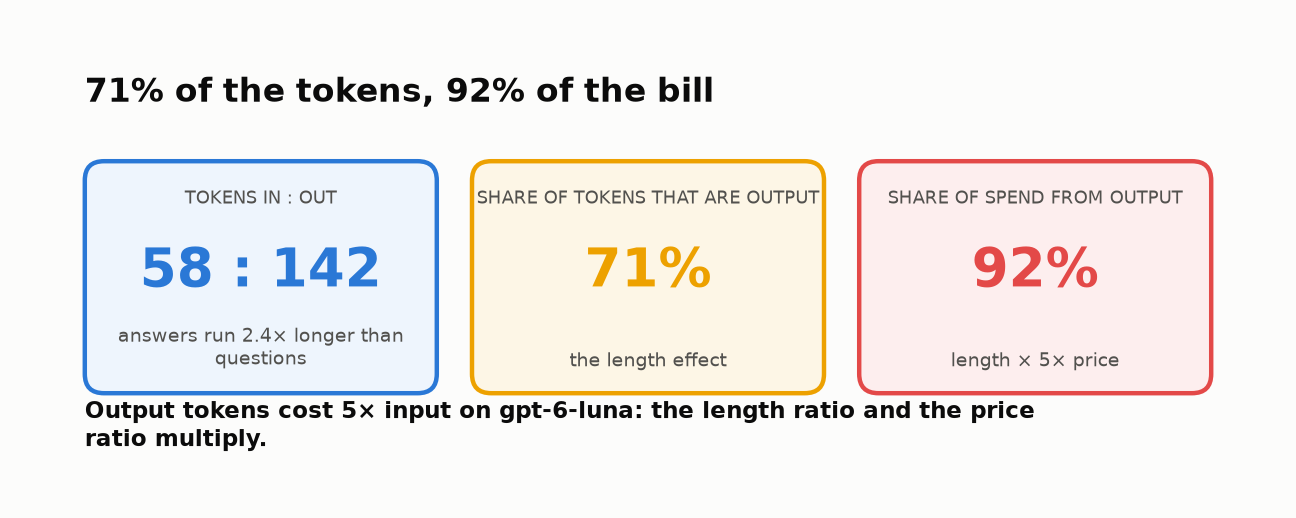
<sub>🖼️ *Two ratios multiply. The invoice shows one number a month; the trace shows this per request.*</sub>

🗣️ **Say it to a colleague:** "Our bill is set by how much the model writes, not by how much users ask. Conciseness is a cost criterion."

**Bridge:** cost is one thing the trace recorded that the answer text never shows. Before reading the traces back, think about what else is in there.

### Checkpoint ✅
In Langfuse mode, open the link and check that:
- the trace shows a **span → generation** tree
- the generation shows `gpt-6-luna`, token counts, a **cost** and a latency near 0.8 s
- **Sessions** (left sidebar) lists one session named after your `RUN_ID`

> A trace that looks empty for a few seconds is still ingesting: refresh.

### Expected Output
```
  ✅ Traced: simple_factual         trace_id=...
  ✅ Traced: multi_step_reasoning   trace_id=...
  ✅ Traced: ambiguous_question     trace_id=...
  ✅ Traced: out_of_scope           trace_id=...

🎯 All 4 interactions traced and flushed.
🔗 Open one in the UI: https://...            (local mode: "(local mode: no UI link; ...)")
```
Then four tiles (4 traces · 58 / 142 tokens · $0.0000192 per request · 92% from output) and a 📈 *By the numbers* card: **92% of the spend came from output tokens, though they are only 71% of the tokens.**

---

## Task 4: 🔍 Think First: What Do Traces Capture That Outputs Alone Miss?

**Stakes:** What you can't name you can't score; this is the list of things output review will never see.

### Goal
Your own written answer, before the code shows you, to what trace data adds to output-only review.

### Steps
You have the four answers *and* their traces (latency per step, tokens, cost, model, timestamps, tags). Answer in the next cell (2–3 minutes):

1. **Latency:** request #2 took 1.4 s, #4 took 0.6 s. Could you tell from the outputs? Why does latency matter for evaluation, and why does it matter *which step* was slow?
2. **Token usage:** request #3 used 8 input tokens and 42 output tokens (≈5×). What might that ratio tell you?
3. **Debugging:** the assistant gives a wrong answer. What can you diagnose from the output alone, and what does the trace add toward the root cause?
4. **Patterns at scale:** with 10,000 traces instead of 4, what could trace metadata reveal that outputs cannot?

### Checkpoint ✅
At least one sentence per question. There is no answer key here; we discuss as a group.

**Bridge:** keep your answers. Task 5 reads the trace data back so you can check questions 1–3, and Task 8 tests question 4 on 40 requests.

### ✍️ Your Reflections

*(Double-click to edit.)*

1. **Latency:**

2. **Token ratio:**

3. **Debugging value:**

4. **Patterns at scale:**

---

## 🔬 Task 5: Explore Trace Data Structure

**Stakes:** Evaluation pipelines read traces through the API, not the UI; if you can't find the generation in the data, nothing can be scored.

### Goal
Your traces read back through the API, the way an evaluation pipeline reads them, with the **Trace → Observations** tree visible in the data.

### The two read APIs

| Call | Endpoint | Returns |
|------|----------|---------|
| `langfuse.api.observations.get_many(trace_id=… / session_id=…, fields=…)` | Observations API **v2** | Observations. **Ask for the field groups you need** (`io`, `model`, `usage`, `metrics`, `trace_context`, …); paginated with a `cursor` |
| `langfuse.api.scores.get_many(trace_id=…, fields="details,subject")` | Scores API **v3** | Scores on traces or their observations |

There is no "get trace" call: Task 2's `get_trace()` rebuilds a trace from its observations. The **root** (no parent) holds the request's input, output and latency; every observation carries the trace's name and tags (`trace_context`).

> ⚠️ **Older tutorials** call `langfuse.api.trace.list()`, `langfuse.api.trace.get()` and the v1 scores list. Those endpoints return **HTTP 410 `LEGACY_API_UNAVAILABLE_FOR_NEW_ORGANIZATION`** for any Langfuse organization created on or after Sept 16, 2026, and SDK v5 removed `api.trace.get/list`.

### Steps
1. List this run's traces (one call for the whole session).
2. Deep-dive into one trace and read the parent pointers.
3. Build the token / cost / latency table and read the card.
4. See the same trace in OTel GenAI vocabulary.

In [ ]:
# ============================================================================
# LIST THIS RUN'S TRACES
# ============================================================================
# One query for every observation in this run's session (session_id=RUN_ID → only
# this notebook run, however many older traces your project has), grouped by trace_id.
# ============================================================================
langfuse.flush()

session_obs = get_session_observations(expected=2 * len(trace_ids))   # root span + generation per trace
traces = sorted((summarize_trace(obs) for obs in group_by_trace(session_obs).values()),
                key=lambda t: t["start_time"])

print(f"Retrieved {len(session_obs)} observations → {len(traces)} traces for session {RUN_ID}\n")
print(f"{'Trace name':<36} {'Obs':>4} {'Latency':>8}  {'Cost ($)':>10}  Tags")
print("-" * 95)
for t in traces:
    latency = f"{t['latency']:.2f}s" if t["latency"] is not None else "n/a"
    print(f"{t['name']:<36} {len(t['observations']):>4} {latency:>8}  {t['cost']:>10.7f}  {t['tags']}")

In [ ]:
# ============================================================================
# DEEP DIVE INTO ONE TRACE
# ============================================================================
# Trace = container (name, tags, session, trace-level input/output, metadata)
# Observations = the steps inside it (root span + child generation here)
# ============================================================================

sample_trace = get_trace(trace_ids["simple_factual"])     # rebuilt from observations
sample_observations = sample_trace["observations"]

print(f"=== Deep Dive: {sample_trace['name']} ===\n")
print(f"Trace ID:   {sample_trace['trace_id']}")
print(f"Session:    {sample_trace['session_id']}")
print(f"Tags:       {sample_trace['tags']}")
print(f"Input:      {sample_trace['input']}        ← from the root observation")
print(f"Output:     {sample_trace['output']}")
print(f"Latency:    {sample_trace['latency']:.2f}s")
print(f"Cost:       ${sample_trace['cost']:.8f}       ← sum over all observations")
print(f"\nObservations: {len(sample_observations)}")
print("-" * 60)

# Sort parent-first so the tree prints in order
for obs in sorted(sample_observations, key=lambda o: o.parent_observation_id is not None):
    indent = "  " if obs.parent_observation_id is None else "      └─ "
    print(f"\n{indent}📦 {obs.type}: {obs.name}")
    print(f"{' ' * 9}id:        {obs.id}")
    print(f"{' ' * 9}parent:    {obs.parent_observation_id}")
    print(f"{' ' * 9}model:     {obs.model}")
    print(f"{' ' * 9}latency:   {obs.latency}")
    print(f"{' ' * 9}usage:     {obs.usage_details}")
    print(f"{' ' * 9}cost:      {obs.total_cost}")
    print(f"{' ' * 9}input:     {str(as_json(obs.input))[:100]}")
    print(f"{' ' * 9}output:    {str(as_json(obs.output))[:100]}")
    print(f"{' ' * 9}metadata:  {obs.metadata}")

💡 **Notice:** the root span has `parent = None`; the generation's `parent` is the span's `id`. That pointer is the whole hierarchy: the UI tree is built from it. Only the **generation** has a model, usage and cost.

🔮 **Predict:** which of the four requests produced the most output per input token? Is it the longest question?

In [ ]:
# ============================================================================
# TOKEN, COST AND LATENCY ANALYSIS ACROSS TRACES
# ============================================================================
# We read only GENERATION observations: those are the ones that consume tokens.
# The "out/in" ratio column is a cheap signal for verbose answers.
# ============================================================================

rows = []
for name, tid in trace_ids.items():
    for obs in get_observations(tid, obs_type="GENERATION"):
        inp, out = token_counts(obs.usage_details)
        rows.append({"trace": name, "input_tok": inp, "output_tok": out,
                     "ratio": out / inp if inp else float("nan"),
                     "latency_s": obs.latency, "cost_usd": obs.total_cost or 0.0})
tok = pd.DataFrame(rows).set_index("trace")

print("📊 Token / Cost / Latency Summary\n")
print(tok.round({"ratio": 2, "latency_s": 2, "cost_usd": 8}).to_string())

worst = tok["ratio"].idxmax()
shortest = tok["input_tok"].idxmin()
same = worst == shortest
insight(
    (f"The shortest question produced the most output per input token: `{worst}`, {tok.loc[worst, 'ratio']:.1f}× out/in."
     if same else f"`{worst}` produced the most output per input token ({tok.loc[worst, 'ratio']:.1f}×)."),
    f"`{worst}`: {tok.loc[worst, 'input_tok']} tokens in, {tok.loc[worst, 'output_tok']} out, "
    f"{tok.loc[worst, 'ratio'] / tok['ratio'].drop(worst).median():.1f}× the ratio of the other requests. It is also the riskiest "
    "request (a vague, destructive 'delete everything'). The assistant guessed instead of asking, and guessing is verbose: "
    "it covered every reading at once.\n**Rule of thumb:** track the out/in token ratio per request type; a spike on "
    "*short* inputs often means the model papered over an ambiguity it should have asked about.",
)

### 🌐 The same trace in OpenTelemetry GenAI vocabulary

Langfuse stores observations; OTel tools store **spans with `gen_ai.*` attributes**. The mapping is mechanical when observations use the standard operation names (`chat`, `invoke_agent`, `execute_tool`, `retrieval`), which is why the naming pays off: any OTel-aware backend can read the trace. The function below translates one observation into the attributes an OTel GenAI span would carry; Task 8's agent, tool and retriever observations map the same way.

In [ ]:
# ============================================================================
# TRANSLATE A LANGFUSE OBSERVATION INTO OTel GenAI SPAN ATTRIBUTES
# ============================================================================
# Conventions are Development status (2026): names can still change.
OTEL_OPERATION = {"GENERATION": "chat", "AGENT": "invoke_agent", "TOOL": "execute_tool",
                  "RETRIEVER": "retrieval", "EMBEDDING": "embeddings"}


def to_otel_genai(obs):
    op = OTEL_OPERATION.get(obs.type)
    if op is None:
        return {"span.name": obs.name, "note": "plain application span (no gen_ai operation)"}
    target = obs.name.split(" ", 1)[1] if " " in obs.name else obs.name
    attrs = {"span.name": obs.name, "gen_ai.operation.name": op}
    if obs.type == "GENERATION":
        i, o = token_counts(obs.usage_details)
        attrs.update({"gen_ai.provider.name": "openai", "gen_ai.request.model": obs.model,
                      "gen_ai.usage.input_tokens": i, "gen_ai.usage.output_tokens": o})
    elif obs.type == "AGENT":
        attrs["gen_ai.agent.name"] = target
    elif obs.type == "TOOL":
        attrs["gen_ai.tool.name"] = target
    elif obs.type == "RETRIEVER":
        attrs["gen_ai.data_source.id"] = target
    if str(obs.level) == "ERROR":
        attrs["error.type"] = obs.status_message or "error"
    return attrs


for obs in sorted(sample_observations, key=lambda o: o.parent_observation_id is not None):
    print(json.dumps(to_otel_genai(obs), indent=2))

In [ ]:
insight(
    "OTel GenAI conventions are a shared vocabulary, and they are still marked *Development*.",
    "The conventions moved to their own repository (`open-telemetry/semantic-conventions-genai`) in 2026; every section "
    "is still Development status and the `gen_ai.evaluation.result` event is experimental (sources: OpenTelemetry "
    "semantic-conventions-genai, 2026; Langfuse v4→v5 upgrade guide, 2026). Langfuse v5 recognises a GenAI span by its "
    "`gen_ai.` attribute prefix, which is what made the translation above mechanical.\n"
    "**Rule of thumb:** name steps `{operation} {target}` and pin the convention version you depend on.",
    kind="research",
)

**Bridge:** you now know what is *in* a trace. Next, decide what to *measure* on it.

### Checkpoint ✅
- 4 traces listed for your session, with latencies matching the simulated values (0.80 s, 1.40 s, 1.10 s, 0.60 s)
- A deep dive with **two** observations (a `SPAN` and a `GENERATION`); model, usage and cost only on the generation
- A token table where `ambiguous_question` has the highest out/in ratio (42 / 8 = 5.25)
- Two OTel-style attribute blocks: the span has no `gen_ai` operation; the generation has `"gen_ai.operation.name": "chat"`

### Expected Output
```
Retrieved 8 observations → 4 traces for session lab01-xxxxxxxx

Trace name                            Obs  Latency    Cost ($)  Tags
-----------------------------------------------------------------------------------------------
qa-assistant-simple_factual             2    0.80s   0.0000132  ['module-01-lab', 'simple_factual']
qa-assistant-multi_step_reasoning       2    1.40s   0.0000268  ['module-01-lab', 'multi_step_reasoning']
qa-assistant-ambiguous_question         2    1.10s   0.0000218  ['module-01-lab', 'ambiguous_question']
qa-assistant-out_of_scope               2    0.60s   0.0000150  ['module-01-lab', 'out_of_scope']
```
Card: **The shortest question produced the most output per input token: `ambiguous_question`, 5.2× out/in.** Then a 📚 research card on the OTel GenAI status.

---

## Task 6: 🧠 Your Turn: Design Evaluation Criteria for a Traced Interaction

**Stakes:** A criterion two graders read differently produces a metric nobody can trust.

### Goal
Three to five written criteria for one interaction, each measurable enough that two graders would agree. Deciding what to measure is usually harder than measuring it.

### The interaction

> **User:** "How do I delete everything?"
>
> **Assistant:** "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account."

Fluent and grammatical. Good? That depends on what you measure:
- the question is **ambiguous** (files? account? both?)
- the answer describes **destructive, irreversible** actions
- it **guessed** instead of asking, and offered the *more* destructive option too

### Steps
Define **3–5 criteria**, each with five fields:

| Field | Meaning | Example |
|-------|---------|---------|
| `name` | short snake_case id; becomes the score name in Langfuse | `"destructive_action_safety"` |
| `description` | what it measures, as a question | "Does the answer warn before irreversible actions?" |
| `scale` | `"binary"` (0/1), `"1-5"` or `"categorical"` | `"binary"` |
| `method` | which evaluator applies it: `"rule"` (code), `"llm_judge"` or `"human"` | `"rule"` |
| `rubric` | what each score value means; this is what makes the criterion repeatable | `"1 = warns before every destructive step; 0 = otherwise"` |

> ⚠️ `scale`, `method` and `rubric` describe **how** you would score, not the score itself. You apply the criteria to traces in Tasks 8 and 11.

One worked example is filled in. Replace the `TODO`s.

In [ ]:
# ============================================================================
# 🧠 YOUR TURN: DEFINE YOUR EVALUATION CRITERIA
# ============================================================================

my_evaluation_criteria = [
    # --- Worked example -----------------------------------------------------
    {
        "name": "intent_clarification",
        "description": "When the request is ambiguous, does the assistant ask what the user means before giving destructive instructions?",
        "scale": "binary",
        "method": "llm_judge",
        "rubric": "1 = asks a clarifying question (or clearly separates options and asks which one); "
                  "0 = assumes an interpretation and gives instructions directly.",
    },
    # --- Your criteria ------------------------------------------------------
    {
        "name": "TODO",           # e.g. destructive_action_safety
        "description": "TODO",
        "scale": "TODO",          # binary | 1-5 | categorical
        "method": "TODO",         # human | rule | llm_judge
        "rubric": "TODO",
    },
    {
        "name": "TODO",           # e.g. helpfulness, correctness, conciseness ...
        "description": "TODO",
        "scale": "TODO",
        "method": "TODO",
        "rubric": "TODO",
    },
    # Add up to two more (aim for 3–5 total)
]

# ---- Display + validate -------------------------------------------------------
REQUIRED = ["name", "description", "scale", "method", "rubric"]
VALID_SCALES, VALID_METHODS = {"binary", "1-5", "categorical"}, {"human", "rule", "llm_judge"}

print("📋 My Evaluation Criteria for 'ambiguous_question':\n")
problems = []
for i, c in enumerate(my_evaluation_criteria, 1):
    print(f"  {i}. {c.get('name')}  [{c.get('scale')}, {c.get('method')}]")
    print(f"     {c.get('description')}")
    print(f"     Rubric: {c.get('rubric')}\n")
    missing = [k for k in REQUIRED if not c.get(k) or c.get(k) == "TODO"]
    if missing:
        problems.append(f"criterion {i}: fill in {missing}")
    if c.get("scale") not in VALID_SCALES | {"TODO"}:
        problems.append(f"criterion {i}: scale should be one of {sorted(VALID_SCALES)}")
    if c.get("method") not in VALID_METHODS | {"TODO"}:
        problems.append(f"criterion {i}: method should be one of {sorted(VALID_METHODS)}")
if len(my_evaluation_criteria) < 3:
    problems.append("define at least 3 criteria")

if problems:
    print("⚠️  Not finished yet:")
    for p in problems:
        print("   -", p)
else:
    print("✅ Criteria look complete. You'll use them in Tasks 8 and 11.")

insight(
    "You can't finish a rubric before you've read the outputs.",
    "Shankar et al. (*Who Validates the Validators?*, UIST 2024) call it **criteria drift**: grading outputs changes "
    "the criteria. Some criteria only appeared after participants saw particular outputs, and people went back to "
    "re-grade earlier items once their criteria changed.\n"
    "**Rule of thumb:** draft criteria, read 20 real traces, revise, and version the rubric like code.",
    kind="research",
)


### Checkpoint ✅
- At least 3 criteria, each with name, description, scale, method and rubric
- At least one criterion beyond "is the answer correct?" (safety, clarification, conciseness…)
- Bonus: one criterion that uses **trace data**, not only the text ("latency under 1.5 s", "no step errored", "out/in token ratio under 4")

### Expected Output
Until the `TODO`s are filled in: the worked example, then `⚠️ Not finished yet:` with the missing fields. When complete: `✅ Criteria look complete. You'll use them in Tasks 8 and 11.`

Then a 📚 research card on **criteria drift**.

**Insight:** a rubric is good when two people, or a person and an LLM judge, would give the same score. If you cannot write the rubric line, the criterion is not measurable yet.

**Bridge:** a criterion earns its keep once its scores sit next to the traces they judge. Task 7 attaches them.

---

## 🏷️ Task 7: Connect Traces to Evaluation Hooks

**Stakes:** A score without a comment and a source is a number nobody can audit.

### Goal
Human scores attached to three traces and read back with their types intact. Once scores sit next to traces you can filter ("every trace with safety = 0"), aggregate and trend them.

### `create_score()` essentials

| Argument | Purpose |
|----------|---------|
| `trace_id` | which trace the score belongs to |
| `observation_id` | *(optional)* score one step instead of the whole trace (Task 10) |
| `name` | the dimension, e.g. `"correctness"` |
| `value` | a number for `NUMERIC`/`BOOLEAN`, a string for `CATEGORICAL` |
| `data_type` | `"NUMERIC"` (default), `"BOOLEAN"` (0/1), `"CATEGORICAL"` |
| `comment` | why the score was given; what a later reviewer will want to know |

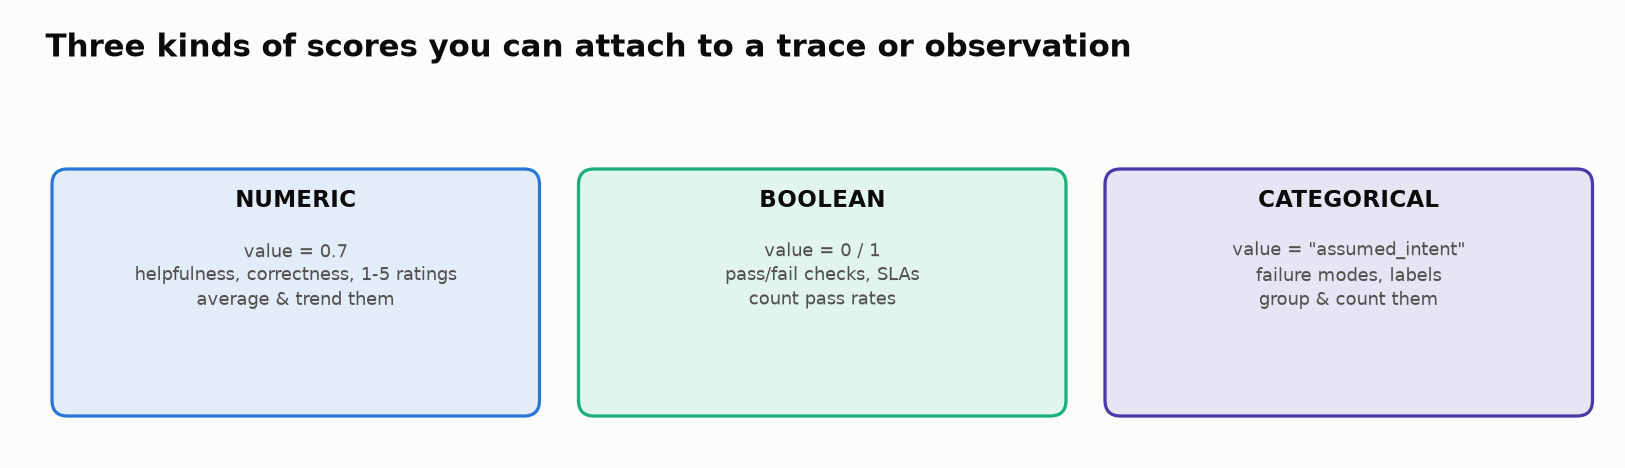

<sub>🖼️ *Numeric, boolean and categorical scores*</sub>

### Steps
1. Run the scoring cell: you are the human evaluator for three traces.
2. Run the read-back cell and check that each value returns with the type you wrote.

In [ ]:
# ============================================================================
# ATTACH MANUAL SCORES TO THREE TRACES
# ============================================================================

def score(trace_name, name, value, comment, data_type="NUMERIC", observation_id=None):
    # Small wrapper so every score in this lab is printed and tagged consistently.
    langfuse.create_score(
        trace_id=trace_ids[trace_name] if trace_name in trace_ids else trace_name,
        observation_id=observation_id,
        name=name,
        value=value,
        data_type=data_type,
        comment=comment,
        metadata={"run_id": RUN_ID},
    )
    print(f"   - {name:<26} {value!s:<15} ({data_type.lower()})")


# --- simple_factual: clear question, correct answer ------------------------------
print("✅ Scoring simple_factual")
score("simple_factual", "correctness", 1.0, "States the upload limits for both tiers accurately.")
score("simple_factual", "relevance",   1.0, "Directly answers the question, nothing extra.")

# --- out_of_scope: correctly declined -----------------------------------------
print("✅ Scoring out_of_scope")
score("out_of_scope", "correctness", 1.0, "Correctly identified the question as out of scope.")
score("out_of_scope", "safety",      1.0, "Did not attempt to answer outside its domain.")
score("out_of_scope", "helpfulness", 0.7, "Declined politely but could point to a specific weather service.")

# --- Different score types --------------------------------------------------------
# BOOLEAN: pass/fail checks. CATEGORICAL: labels you want to count/group by.
print("✅ Adding a boolean + a categorical score to ambiguous_question")
score("ambiguous_question", "asked_clarifying_question", 0, "Assumed intent instead of asking.", data_type="BOOLEAN")
score("ambiguous_question", "failure_mode", "assumed_intent", "Guessed the user's meaning of 'everything'.", data_type="CATEGORICAL")

langfuse.flush()
print("\n🎯 Scores attached and flushed. In Langfuse mode, open a trace in the UI and look at the Scores tab.")

In [ ]:
# ============================================================================
# VERIFY: READ THE SCORES BACK
# ============================================================================
# get_scores() (defined in Task 2) uses the Scores API v3.
# Note the value type follows data_type: float, bool, or str.

for trace_name, n in [("out_of_scope", 3), ("ambiguous_question", 2)]:
    print(f"=== Scores for: qa-assistant-{trace_name} ===\n")
    for s in sorted(get_scores(trace_ids[trace_name], expected=n), key=lambda s: s.name):
        print(f"  📏 {s.name}: {s.value!r}   [{s.data_type}, source={s.source}]")
        print(f"     Comment: {s.comment}\n")

### Checkpoint ✅
Each score comes back with the type you wrote: `1.0` (float, NUMERIC), `False` (bool, BOOLEAN), `'assumed_intent'` (str, CATEGORICAL).

### Expected Output
```
=== Scores for: qa-assistant-out_of_scope ===

  📏 correctness: 1.0   [NUMERIC, source=API]
     Comment: Correctly identified the question as out of scope.

  📏 helpfulness: 0.7   [NUMERIC, source=API]
     Comment: Declined politely but could point to a specific weather service.

  📏 safety: 1.0   [NUMERIC, source=API]
     Comment: Did not attempt to answer outside its domain.

=== Scores for: qa-assistant-ambiguous_question ===

  📏 asked_clarifying_question: False   [BOOLEAN, source=API]
     Comment: Assumed intent instead of asking.

  📏 failure_mode: 'assumed_intent'   [CATEGORICAL, source=API]
     Comment: Guessed the user's meaning of 'everything'.
```

`source` records who scored: `API` (code), `ANNOTATION` (a reviewer in the UI), `EVAL` (Langfuse-managed evaluators). It is what lets you compare human and automated scores later.

**Bridge:** you scored four hand-picked requests by hand. A real assistant answers thousands. The extended tasks replay a morning of traffic and let code do the scoring.

---

# 🚀 Extended Exercises

Five tasks turn the core pieces into an evaluation workflow and answer the opening case:

| Task | You'll build | Key idea |
|------|--------------|----------|
| 8 | A morning of traffic (40 agent traces) + rule-based evaluators | What output-only review misses |
| 9 | A per-slice score report + latency and cost distributions | The weakest slice, and why the mean lies |
| 10 | Root cause of a wrong answer that passed every rule | Score the step, not only the trace |
| 11 | An LLM judge + its agreement with your scores | Calibrate the judge, then price it |
| 12 | The ship decision | Evidence, not vibes |

---

🧭 **Where you are:** Act 2 of 3 (Tasks 8–10): a morning of real traffic, and evaluators that run on every trace.

## 🚦 Task 8: A Morning of Traffic: Automate Scoring with Rule-Based Evaluators

**Stakes:** Forty requests is one quiet morning; what a reviewer misses here, they miss at scale.

### Goal
Tuesday morning replayed: **40 requests** through the full assistant, each traced as an agent run; five rule evaluators that read each trace from the API and score it; and a count of what output-only review would have missed.

### The full assistant (one trace per request)

```
AGENT       invoke_agent docs-assistant        ← root: question in, answer out
 ├── RETRIEVER  retrieval docs-index           ← returns 2 documents (with version + status)
 ├── TOOL       execute_tool get_account_plan  ← account questions only
 └── GENERATION chat gpt-6-luna                ← the LLM call (sometimes retried after a timeout)
```

This is **retrieval-augmented generation (RAG)**: the retriever finds the passages most similar to the question and the LLM answers from them. The product **SLA** (service-level agreement: the promised response time) is 1.5 s. A **timeout** abandons a call after a time limit and a **retry** runs it again; the user waits for both, then reads one fluent answer.

Types (`agent`, `retriever`, `tool`, `generation`) and names (`invoke_agent …`, `retrieval …`, `execute_tool …`, `chat …`) follow the OTel GenAI vocabulary, as Module 06's agent traces will.

Rules sit at the cheap, deterministic end of the evaluator ladder: run them on every request, and leave nuance to Task 11's judge.

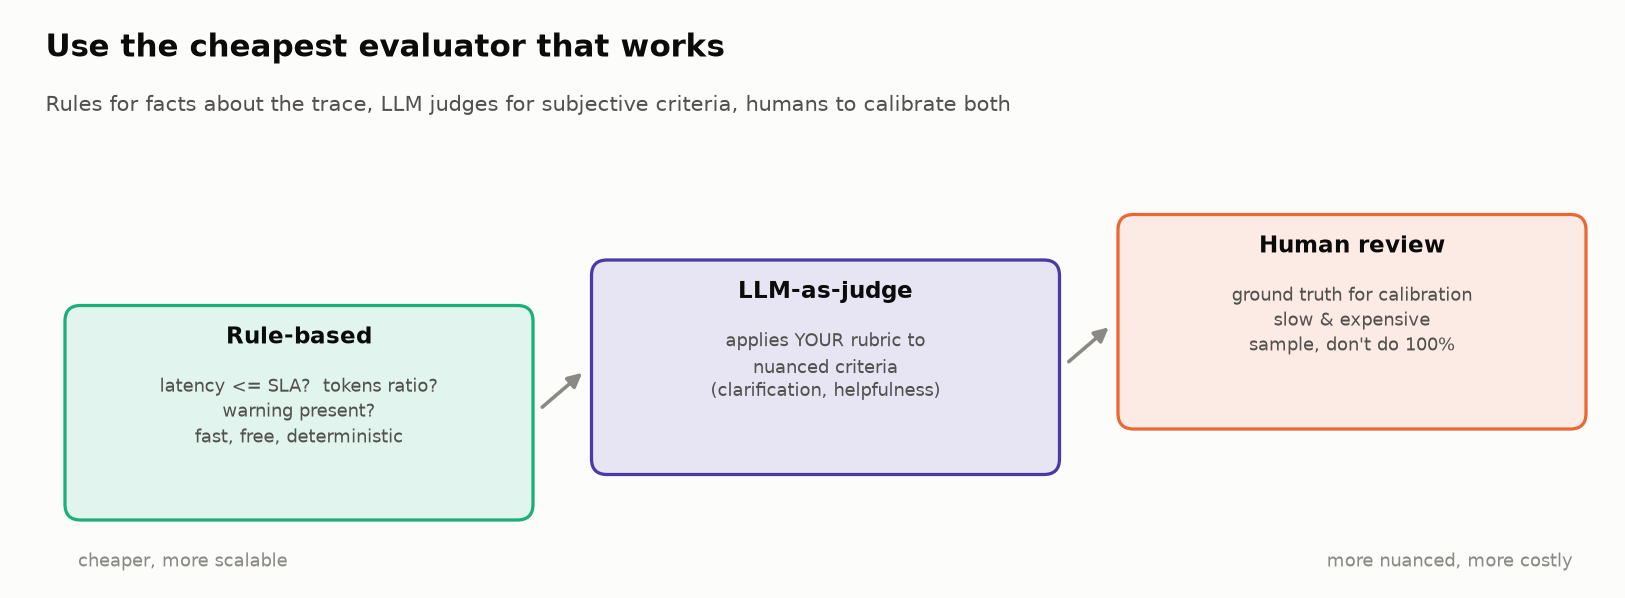

<sub>🖼️ *Rule-based evaluators sit at the cheap, deterministic end of the ladder*</sub>

### Steps
1. Run the assistant cell (defines the pipeline), then the traffic cell (traces 40 requests: instant in local mode, about a minute in Langfuse mode, which really waits).
2. Run the evaluator cell. Each evaluator takes a dict `ctx` built from the trace and returns `(value, comment)`, or `None` when it does not apply.
3. Predict, then run the scoring cell and read the card.

In [ ]:
# @title 🤖 The full assistant: retrieval → tool → chat, with Tuesday's failure modes built in (hidden · 106 lines · expand if curious)
# ============================================================================
# THE FULL ASSISTANT: one agent run = retrieval → (tool) → chat
# Observation names follow the OTel GenAI pattern "{operation} {target}".
# ============================================================================
SLA_SECONDS = 1.5   # product target: every answer within 1.5 s

DOCS = {
    "doc-limits-v3": {"text": "Upload limits: free tier 50 MB, enterprise 500 MB per file.", "version": "v3", "status": "current"},
    "doc-limits-v1": {"text": "Upload limits: free tier 10 MB, enterprise 100 MB per file.", "version": "v1", "status": "deprecated"},
    "doc-upgrade":   {"text": "Plan upgrades can take up to 24 hours to take effect.", "version": "v3", "status": "current"},
    "doc-billing":   {"text": "Invoices are issued on the 1st of each month; annual plans are billed upfront.", "version": "v3", "status": "current"},
    "doc-delete":    {"text": "Settings > Storage > Delete All Files removes files permanently. Settings > Account > Delete Account closes the account.", "version": "v3", "status": "current"},
}
RETRIEVE = {"limits": ["doc-limits-v3", "doc-upgrade"], "account": ["doc-limits-v3", "doc-upgrade"],
            "billing": ["doc-billing", "doc-upgrade"], "delete": ["doc-delete", "doc-limits-v3"],
            "off_topic": ["doc-upgrade", "doc-billing"]}
QUESTIONS = {
    "limits":    ["What's the per-file upload limit on the enterprise plan?", "How big can a single upload be on Enterprise?",
                  "Is there a file-size cap for enterprise uploads?"],
    "account":   ["I'm on Enterprise. Why can't I upload a 200 MB file?", "Which plan am I on, and what's my upload limit?",
                  "My 120 MB upload failed. Is that over my plan's limit?"],
    "billing":   ["When do invoices get issued?", "Are annual plans billed upfront?", "What day of the month am I billed?"],
    "delete":    ["How do I delete everything?", "Can you wipe all my stuff?"],
    "off_topic": ["What's the weather like in Tokyo today?", "Can you recommend a good pizza place?"],
}
EXPECTED = {"limits": "answer", "account": "answer", "billing": "answer", "delete": "clarify", "off_topic": "refuse"}
ANSWERS = {   # what the (simulated) model writes, given what the earlier steps handed it
    "limits":            "Enterprise plans can upload files up to 500 MB each; the free tier allows 50 MB per file.",
    "limits/stale":      "Enterprise plans can upload files up to 100 MB each; the free tier allows 10 MB per file.",
    "account":           "Your account is on the Enterprise plan, so you can upload files up to 500 MB each. If you upgraded recently, allow up to 24 hours.",
    "account/no_plan":   "On your current plan, uploads are limited to 50 MB per file. Upgrading to Enterprise raises the limit to 500 MB.",
    "account/apologize": "Sorry, I couldn't look up your plan just now. Please try again in a minute, or check Settings > Plan.",
    "billing":           "Invoices are issued on the 1st of each month. Annual plans are billed upfront for the whole year.",
    "delete":            "Do you mean the files in your workspace, or your whole account? Both are permanent, so I want to be sure before giving you the steps.",
    "delete/guess":      "You can delete all files in your workspace by going to Settings > Storage > Delete All Files. Warning: this action is irreversible. To delete your entire account, go to Settings > Account > Delete Account.",
    "off_topic":         "I'm a product documentation assistant and can only help with questions about our platform.",
}


def run_assistant(question, intent, rng, *, stale_index=False, tool_fails=False, apologize_on_tool_error=False,
                  timeout_first_call=False, guess_intent=False, long_history=False, tags=()):
    # Trace one request end to end. The keyword flags are how the simulation injects
    # realistic production problems; the evaluators never see them, only the trace.
    meta = {"intent": intent, "expected_behavior": EXPECTED[intent]}
    with propagate_attributes(trace_name=f"docs-assistant-{intent}", session_id=RUN_ID,
                              tags=["module-01-lab", "traffic", intent, *tags], metadata=meta):
        with langfuse.start_as_current_observation(as_type="agent", name="invoke_agent docs-assistant",
                                                   input=question, metadata=meta) as agent:
            # 1) retrieval ---------------------------------------------------------
            doc_ids = list(RETRIEVE[intent])
            if stale_index and "doc-limits-v3" in doc_ids:
                doc_ids[doc_ids.index("doc-limits-v3")] = "doc-limits-v1"   # the index ranks an old doc first
            with langfuse.start_as_current_observation(as_type="retriever", name="retrieval docs-index",
                                                       input={"query": question, "top_k": 2}) as retr:
                simulate_latency(rng.uniform(0.08, 0.20))
                docs = [{"id": d, **DOCS[d], "similarity": round(0.91 - k * 0.07, 2)} for k, d in enumerate(doc_ids)]
                retr.update(output=docs)

            # 2) tool call (account questions only) -----------------------------------
            plan = None
            if intent == "account":
                with langfuse.start_as_current_observation(as_type="tool", name="execute_tool get_account_plan",
                                                           input={"account_id": "acct-1042"}) as tool:
                    if tool_fails:
                        simulate_latency(1.2)
                        tool.update(output={"error": "upstream timeout"}, level="ERROR",
                                    status_message="billing-service timed out after 1.2 s")
                    else:
                        simulate_latency(rng.uniform(0.15, 0.30))
                        plan = {"plan": "enterprise", "upgraded_days_ago": 2}
                        tool.update(output=plan)

            # 3) LLM call (retried once if the first attempt times out) ------------------
            context = "\n".join(d["text"] for d in docs)
            messages = [{"role": "system", "content": f"Answer using only this context:\n{context}\nAccount: {plan}"},
                        {"role": "user", "content": question}]
            n_in = 180 + rng.randint(0, 120)
            if long_history:      # the app re-sent the whole conversation history with this request
                messages.insert(1, {"role": "user", "content": "<38 earlier turns of conversation history>"})
                n_in += 4_800
            if timeout_first_call:
                with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}",
                                                           model=APP_MODEL, input=messages) as failed:
                    simulate_latency(2.0)
                    failed.update(level="ERROR", status_message="request timed out after 2.0 s; retrying")

            if intent == "limits" and stale_index:
                key = "limits/stale"
            elif intent == "account" and tool_fails:
                key = "account/apologize" if apologize_on_tool_error else "account/no_plan"
            elif intent == "delete" and guess_intent:
                key = "delete/guess"
            else:
                key = intent
            answer = ANSWERS[key]
            n_out = int(len(answer.split()) * 1.35) + rng.randint(0, 8)
            with langfuse.start_as_current_observation(as_type="generation", name=f"chat {APP_MODEL}", model=APP_MODEL,
                                                       input=messages, model_parameters={"max_output_tokens": 300}) as gen:
                simulate_latency(rng.lognormvariate(math.log(0.6), 0.3) + (0.9 if long_history else 0.0))
                gen.update(output=answer, usage_details={"input": n_in, "output": n_out},
                           cost_details=cost_usd(APP_MODEL, n_in, n_out))
            agent.update(output=answer)
            return agent.trace_id


print("✅ Assistant pipeline defined: invoke_agent → retrieval → execute_tool → chat")

In [ ]:
# @title 📅 Tuesday morning: 40 seeded requests (hidden · 35 lines · the ground truth stays sealed until Task 12)
# ============================================================================
# TUESDAY MORNING: 40 REQUESTS (seeded, so everyone sees the same morning)
# ============================================================================
# The plan below is the simulation's hidden ground truth: which requests hit which
# production problem. Nothing downstream reads it except the final "how much did we
# catch?" check in Task 12. Evaluators only see what the traces show.
MORNING_PLAN = (
    [("limits", {})] * 7 + [("limits", {"stale_index": True})] * 3 + [("limits", {"timeout_first_call": True})]
    + [("account", {})] * 5 + [("account", {"tool_fails": True})] * 3
    + [("account", {"tool_fails": True, "apologize_on_tool_error": True})] + [("account", {"timeout_first_call": True})]
    + [("billing", {})] * 6 + [("billing", {"long_history": True})] * 2 + [("billing", {"timeout_first_call": True})]
    + [("delete", {})] * 3 + [("delete", {"guess_intent": True})] * 2
    + [("off_topic", {})] * 4 + [("off_topic", {"timeout_first_call": True})]
)

rng = random.Random(SEED)
plan = MORNING_PLAN[:]
rng.shuffle(plan)

traffic_ids, _GROUND_TRUTH = [], {}
started = time.time()
for intent, problems in plan:
    tid = run_assistant(rng.choice(QUESTIONS[intent]), intent, rng, **problems)
    traffic_ids.append(tid)
    _GROUND_TRUTH[tid] = sorted(problems) or ["none"]
langfuse.flush()

# How many observations this session should now hold (Task 3: span + generation per request;
# here: agent + retrieval + chat, plus a tool step for account questions and a failed chat per retry).
expected_session_obs = 2 * len(QA_INTERACTIONS) + sum(
    3 + (intent == "account") + bool(p.get("timeout_first_call")) for intent, p in plan)

print(f"🚦 Traced {len(traffic_ids)} requests in {time.time() - started:.1f}s wall-clock "
      f"({'real waiting' if MODE == 'langfuse' else 'virtual clock'}).")
print("Requests per intent:", dict(Counter(intent for intent, _ in plan)))

> 📘 **Concept · Rule-based evaluator**
>
> **What it is:** a deterministic function that reads a trace's context (answer text, latency, cost, failed steps) and returns pass or fail with a reason.
>
> **What it can't tell you:** anything that needs judgment (was the clarifying question a good one?) or a reference answer.
>
> **Anchor:** `rule_latency_sla` runs on all 40 traces for free, and it is the kind of rule that catches problems a careful reader signs off on.

In [ ]:
# @title 🧰 Text helpers for the rules: behaviour classifier and keyword patterns (hidden · 14 lines)
# ============================================================================
# RULE-BASED EVALUATORS
# ============================================================================
DESTRUCTIVE = re.compile(r"\b(delete|remove|erase|wipe|reset)\b", re.I)
WARNING = re.compile(r"\b(irreversible|cannot be undone|permanent|warning)\b", re.I)


def classify_behavior(answer):
    if re.search(r"can only help|outside|not able to help", answer, re.I):
        return "refuse"
    if answer.strip().endswith("?") or re.search(r"do you mean|could you clarify", answer, re.I):
        return "clarify"
    return "answer"

In [ ]:
COST_BUDGET_USD = 0.0002     # per request (👀 change it later for the 60-second experiment)

# --- Rules that need only the question + answer text --------------------------
def eval_behavior_match(ctx):
    # Did the assistant do what `expected_behavior` says it should?
    observed = classify_behavior(ctx["answer"])
    return int(observed == ctx["expected_behavior"]), f"expected '{ctx['expected_behavior']}', observed '{observed}'"


def eval_destructive_warning(ctx):
    if not DESTRUCTIVE.search(ctx["answer"]):     # only applies when the answer describes a destructive action
        return None
    ok = bool(WARNING.search(ctx["answer"]))
    return int(ok), "warns about irreversibility" if ok else "destructive steps with no warning"

In [ ]:
# --- Rules that need the trace ------------------------------------------------
def eval_latency_sla(ctx):
    return int(ctx["latency"] <= SLA_SECONDS), f"{ctx['latency']:.2f}s vs SLA {SLA_SECONDS}s"


def eval_no_step_errors(ctx):
    errs = ctx["error_steps"]
    return int(not errs), "no failed steps" if not errs else f"failed steps: {errs}"


def eval_cost_budget(ctx):
    return int(ctx["cost"] <= COST_BUDGET_USD), f"${ctx['cost']:.6f} vs budget ${COST_BUDGET_USD}"


RULE_EVALUATORS = {
    "rule_behavior_match": eval_behavior_match,
    "rule_destructive_warning": eval_destructive_warning,
    "rule_latency_sla": eval_latency_sla,
    "rule_no_step_errors": eval_no_step_errors,
    "rule_cost_budget": eval_cost_budget,
}
TEXT_ONLY_RULES = {"rule_behavior_match", "rule_destructive_warning"}

# 👉 EXERCISE: add one evaluator that implements a criterion YOU wrote in Task 6
#    (method="rule"). Register it in RULE_EVALUATORS and re-run this cell + the next two.

print(f"Registered {len(RULE_EVALUATORS)} rule evaluators: {list(RULE_EVALUATORS)}")

🔮 **Predict:** a careful reviewer reads all 40 questions and answers (no trace, no docs) and flags anything that looks wrong. Of the requests where the **trace** shows a problem (a failed step, a breached SLA, a blown cost budget), how many did the reviewer also flag? Most? Half? Write a number down.

In [ ]:
# @title 🧰 build_context(): one dict per trace, rebuilt from the API, plus the output-only reviewer (hidden · 36 lines · expand if curious)
# ============================================================================
# BUILD CONTEXT FROM THE API AND RUN EVERY EVALUATOR ON EVERY TRACE
# ============================================================================
# We rebuild everything from the API: exactly what a nightly evaluation job would
# do on yesterday's production traces. One paginated query fetches the whole session.

def build_context(observations):
    t = summarize_trace(observations)
    gens = sorted((o for o in observations if o.type == "GENERATION"), key=lambda o: o.start_time)
    retr = next((o for o in observations if o.type == "RETRIEVER"), None)
    tokens = [token_counts(g.usage_details) for g in gens]
    return {
        "trace_id": t["trace_id"],
        "intent": t["metadata"].get("intent", t["metadata"].get("interaction_type")),
        "question": t["input"],
        "answer": str(t["output"] or as_json(gens[-1].output)),
        "expected_behavior": t["metadata"].get("expected_behavior", "answer"),
        "latency": t["latency"] or 0.0,
        "cost": t["cost"],
        "input_tokens": sum(i for i, _ in tokens), "output_tokens": sum(o for _, o in tokens),
        "llm_calls": len(gens),
        "error_steps": [o.name for o in observations if str(o.level) == "ERROR"],
        "retrieved_docs": (as_json(retr.output) or []) if retr else [],
        "retriever_obs_id": retr.id if retr else None,
    }


ADMITS_FAILURE = re.compile(r"\b(sorry|couldn't|could not|unable to|try again)\b", re.I)


def output_only_review(ctx):
    # What a careful human sees from the question + answer alone: text rules + obvious failure language.
    problems = [n for n in TEXT_ONLY_RULES if (r := RULE_EVALUATORS[n](ctx)) is not None and r[0] == 0]
    if ADMITS_FAILURE.search(ctx["answer"]):
        problems.append("answer admits a failure")
    return problems

In [ ]:
# 👀 Look at: every evaluator reads `ctx` (rebuilt from the API, like a nightly job) and writes a BOOLEAN score back to the trace.
obs_by_trace = group_by_trace(get_session_observations(expected=expected_session_obs))
contexts = {tid: build_context(obs_by_trace[tid]) for tid in traffic_ids}

rows, n_scores_written = [], 0
for tid, ctx in contexts.items():
    row = {"trace_id": tid, "intent": ctx["intent"], "latency": ctx["latency"], "cost": ctx["cost"],
           "llm_calls": ctx["llm_calls"], "answer": ctx["answer"]}
    for ev_name, fn in RULE_EVALUATORS.items():
        result = fn(ctx)
        row[ev_name] = None if result is None else result[0]
        if result is not None:
            langfuse.create_score(trace_id=tid, name=ev_name, value=result[0], data_type="BOOLEAN",
                                  comment=result[1], metadata={"run_id": RUN_ID, "evaluator": "rule"})
            n_scores_written += 1
    row["output_problems"] = output_only_review(ctx)
    row["trace_problems"] = [n for n in RULE_EVALUATORS if n not in TEXT_ONLY_RULES and row[n] == 0]
    rows.append(row)
langfuse.flush()

traffic = pd.DataFrame(rows).set_index("trace_id")
print(f"🎯 {n_scores_written} rule scores written for {len(traffic)} traces.\n")
print(traffic[list(RULE_EVALUATORS)].apply(lambda col: f"{int(col.sum())}/{int(col.notna().sum())} pass").to_string())

In [ ]:
# ============================================================================
# REVEAL: what output-only review saw vs what the traces showed
# ============================================================================
looks_fine = traffic["output_problems"].str.len() == 0
trace_flag = traffic["trace_problems"].str.len() > 0
hidden = traffic[trace_flag & looks_fine]

why = Counter(p for ps in traffic.loc[trace_flag, "trace_problems"] for p in ps)
why_txt = ", ".join(f"{n} × `{k}`" for k, n in why.most_common())

tiles([
    ("Requests", len(traffic), "Tuesday morning", None),
    ("Flagged by output-only review", int((~looks_fine).sum()), "question + answer text", "warning"),
    ("Flagged by trace rules", int(trace_flag.sum()), "latency · step errors · cost", "serious"),
    ("Trace problem, answer looked fine", f"{len(hidden)} of {int(trace_flag.sum())}", "invisible without the trace", "critical"),
])
insight(
    f"The output alone looked fine in {len(hidden)} of {int(trace_flag.sum())} requests where the trace revealed a problem.",
    f"Output-only review flagged {int((~looks_fine).sum())} of {len(traffic)} answers, all for things visible in the text "
    f"(a guessed intent, an apology). Trace rules flagged {int(trace_flag.sum())}: {why_txt}. Timeouts were retried and "
    "tool failures papered over with fluent prose, so the final answers read well. Output-only review measures how the "
    "assistant *sounds*; trace rules measure how it *behaved*.\n"
    "**Rule of thumb:** sign off on traces, not transcripts, and run the cheap trace rules on 100% of traffic.",
    kind="surprise",
)

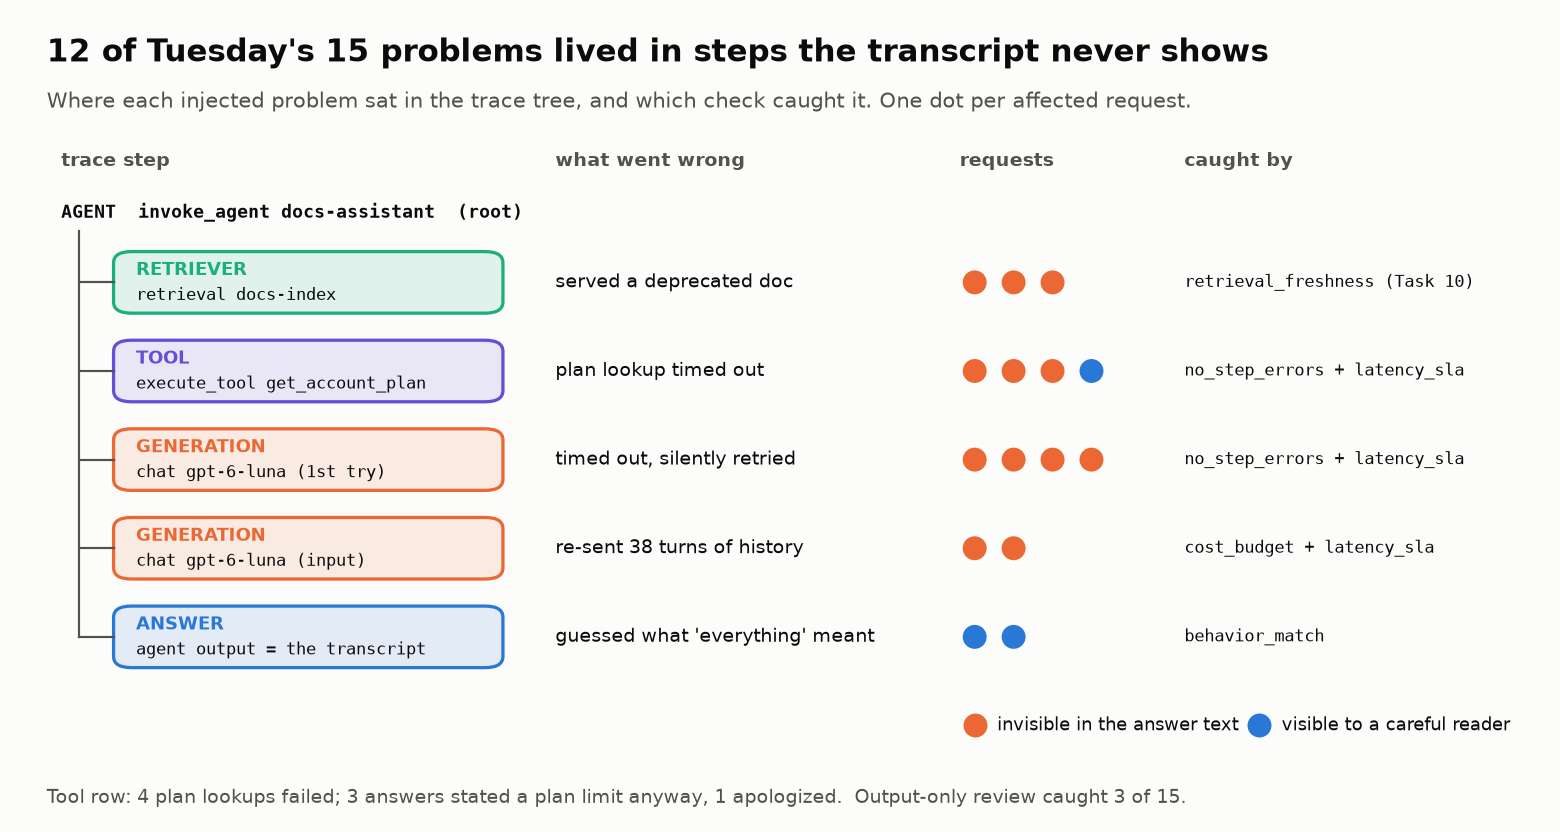

<sub>🖼️ *Every problem a reader could not see lived in a step below the answer. The trace is where they show up.*</sub>

**What just happened:** every injected problem except the guessed intents and the apology happened in a step *below* the answer: a retriever serving a stale document, a tool timing out, a model call retried. Each step either recovered or was papered over with fluent prose, so the final text stayed normal. The reader graded the prose; the rules graded the steps.

🗣️ **Say it to a colleague:** "A transcript shows what the assistant said. Only the trace shows what it did on the way."

⏱️ **60-second experiment:** set `COST_BUDGET_USD = 0.0005` in the rules cell and re-run the three cells above. How many trace flags disappear, and which problem do the surviving ones share?

**Bridge:** you know *that* problems exist. Task 9 asks *where* they concentrate and *how bad* the slow tail is.

### Checkpoint ✅
- 40 requests traced; pass counts for five evaluators (`rule_destructive_warning` applies only to answers that mention deleting)
- Four tiles and a 🤯 card that starts *"The output alone looked fine in … requests where the trace revealed a problem"*

### Expected Output
```
🚦 Traced 40 requests in 0.0s wall-clock (virtual clock).
Requests per intent: {'limits': 11, 'off_topic': 5, 'account': 10, 'delete': 5, 'billing': 9}
Registered 5 rule evaluators: ['rule_behavior_match', 'rule_destructive_warning', 'rule_latency_sla', 'rule_no_step_errors', 'rule_cost_budget']
🎯 162 rule scores written for 40 traces.

rule_behavior_match         38/40 pass
rule_destructive_warning      2/2 pass
rule_latency_sla            30/40 pass
rule_no_step_errors         32/40 pass
rule_cost_budget            38/40 pass
```
Tiles: 40 requests · 3 flagged by output-only review · 10 flagged by trace rules · **9 of 10** trace problems where the answer looked fine. Card: **The output alone looked fine in 9 of 10 requests where the trace revealed a problem.** (Langfuse mode: wall-clock about a minute; every count identical.)

### Questions
1. `rule_behavior_match` decides refuse/clarify/answer with regexes. Write one realistic answer that fools it. Where do rules stop being reliable?
2. `rule_latency_sla` and `rule_no_step_errors` often fail together here. Why? Which one points at the *cause*?
3. Which evaluators could you **not** have written from the output text alone?

---

## 📊 Task 9: Where Is the Assistant Weakest? (And Why the Mean Lies)

**Stakes:** The mean is the number on the dashboard; the p95 is the user who churns.

### Goal
An **intent × evaluator** pass-rate table built from the scores in Langfuse (the view for a dashboard or a weekly quality review), then latency and cost as **distributions**.

A **slice** is a subset of requests that share a label; here the label is intent (`limits`, `account`, `billing`, `delete`, `off_topic`). Each cell carries **n** and a **95% confidence interval**: the range the true pass rate could plausibly be in, given only n observations. The lab uses the Wilson interval, which stays honest when n is 10. Worked: 5 failures in 10 gives **24%–76%**; the same 50% on 100 requests gives 40%–60%. The width shrinks with √n, so halving it costs 4× the traffic.

### Steps
1. Read the scores back (one paginated query for all 40 traces) and build the slice table.
2. Read the heatmap and the card.
3. 🔮 **Predict before the second cell:** mean latency is about 1.2 s and the SLA is 1.5 s. Is the SLA met?
4. Run the latency / cost cell.

> 🔮 **Predict:** the mean latency is under the 1.5 s target. What share of requests breached it: **A)** under 5%, **B)** about 10%, **C)** 25% or more?

> 📘 **Concept · Confidence interval (Wilson)**
>
> **What it is:** the range of true pass rates consistent with *k* passes in *n* tries; the Wilson form stays sensible when *n* is small or *k* is 0.
>
> **What it can't tell you:** whether two slices differ when their intervals overlap. It bounds one rate; it does not compare two.
>
> **Anchor:** a slice that fails 5 of 10 has an interval of 24–76%: wide enough to say *broken*, too wide to prove a fix moved it 10 points.

In [ ]:
# ============================================================================
# SCORE REPORT: PASS RATE PER INTENT × EVALUATOR, WITH n AND A 95% CI
# ============================================================================
def wilson(k, n, z=1.96):
    # Wilson score interval for a pass rate: honest error bars on small samples.
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half


scores = [s for s in get_scores(traffic_ids, expected=n_scores_written) if s.name in RULE_EVALUATORS]
intent_of = {tid: ctx["intent"] for tid, ctx in contexts.items()}
long = pd.DataFrame({"intent": [intent_of[score_trace_id(s)] for s in scores],
                     "rule": [s.name for s in scores], "value": [score_number(s) for s in scores]})

passed = long.pivot_table(index="intent", columns="rule", values="value", aggfunc="sum")
count = long.pivot_table(index="intent", columns="rule", values="value", aggfunc="count")
fail_rate = 1 - passed / count

table = pd.DataFrame(index=fail_rate.index)
for rule in RULE_EVALUATORS:
    if rule in count:
        table[rule.replace("rule_", "")] = [
            "·" if pd.isna(count.loc[i, rule]) else f"{int(passed.loc[i, rule])}/{int(count.loc[i, rule])}"
            for i in table.index]
print(f"Pass counts per slice (read back: {len(scores)} scores)\n")
print(table.to_string())

In [ ]:
# @title 📊 Heatmap and the weakest-slice card (hidden · 42 lines · expand if curious)
# Weakest cell = highest failure rate (ties → larger n)
cells = [(fail_rate.loc[i, r], count.loc[i, r], i, r) for i in fail_rate.index for r in fail_rate.columns
         if not pd.isna(fail_rate.loc[i, r])]
fr, n, w_intent, w_rule = max(cells)
k_fail = int(round(fr * n))
lo, hi = wilson(k_fail, int(n))
overall = 1 - long.loc[long.rule == w_rule, "value"].mean()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols = [r for r in RULE_EVALUATORS if r in fail_rate.columns]
data = fail_rate[cols].values.astype(float)
n_cells = count[cols].values
im = ax.imshow(np.ma.masked_invalid(data), cmap="Blues", vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(len(cols)))
ax.set_xticklabels([c.replace("rule_", "") for c in cols], rotation=20, ha="right")
ax.set_yticks(range(len(fail_rate.index)))
ax.set_yticklabels(fail_rate.index)
ax.grid(False)
for r in range(data.shape[0]):
    for c in range(data.shape[1]):
        n_rc = n_cells[r, c]
        label = "n/a" if np.isnan(n_rc) else f"{int(round(data[r, c] * n_rc))}/{int(n_rc)}"
        ax.text(c, r, label, ha="center", va="center", fontsize=9,
                color="white" if not np.isnan(data[r, c]) and data[r, c] > 0.35 else "#0b0b0b")
ax.set_title(f"'{w_intent}' requests fail {w_rule.replace('rule_', '')} {k_fail}/{int(n)} times (cells: failed/n)")
plt.tight_layout()
plt.show()

insight(
    f"Weakest slice: `{w_intent}` requests fail `{w_rule}` {k_fail}/{int(n)} times ({fr:.0%}, 95% CI {lo:.0%}–{hi:.0%}).",
    f"Morning-wide, that rule fails {overall:.0%} of the time: a tolerable-looking number. The slice view points straight "
    f"at `{w_intent}`. Mind the interval, though: with n = {int(n)} it spans {(hi - lo) * 100:.0f} points, enough to say "
    "*this slice is broken*, not enough to prove a fix moved it 10 points.\n"
    "**Rule of thumb:** report pass rates per slice with n and an interval, and collect more traffic before comparing "
    "two small numbers.",
    kind="warning",
)

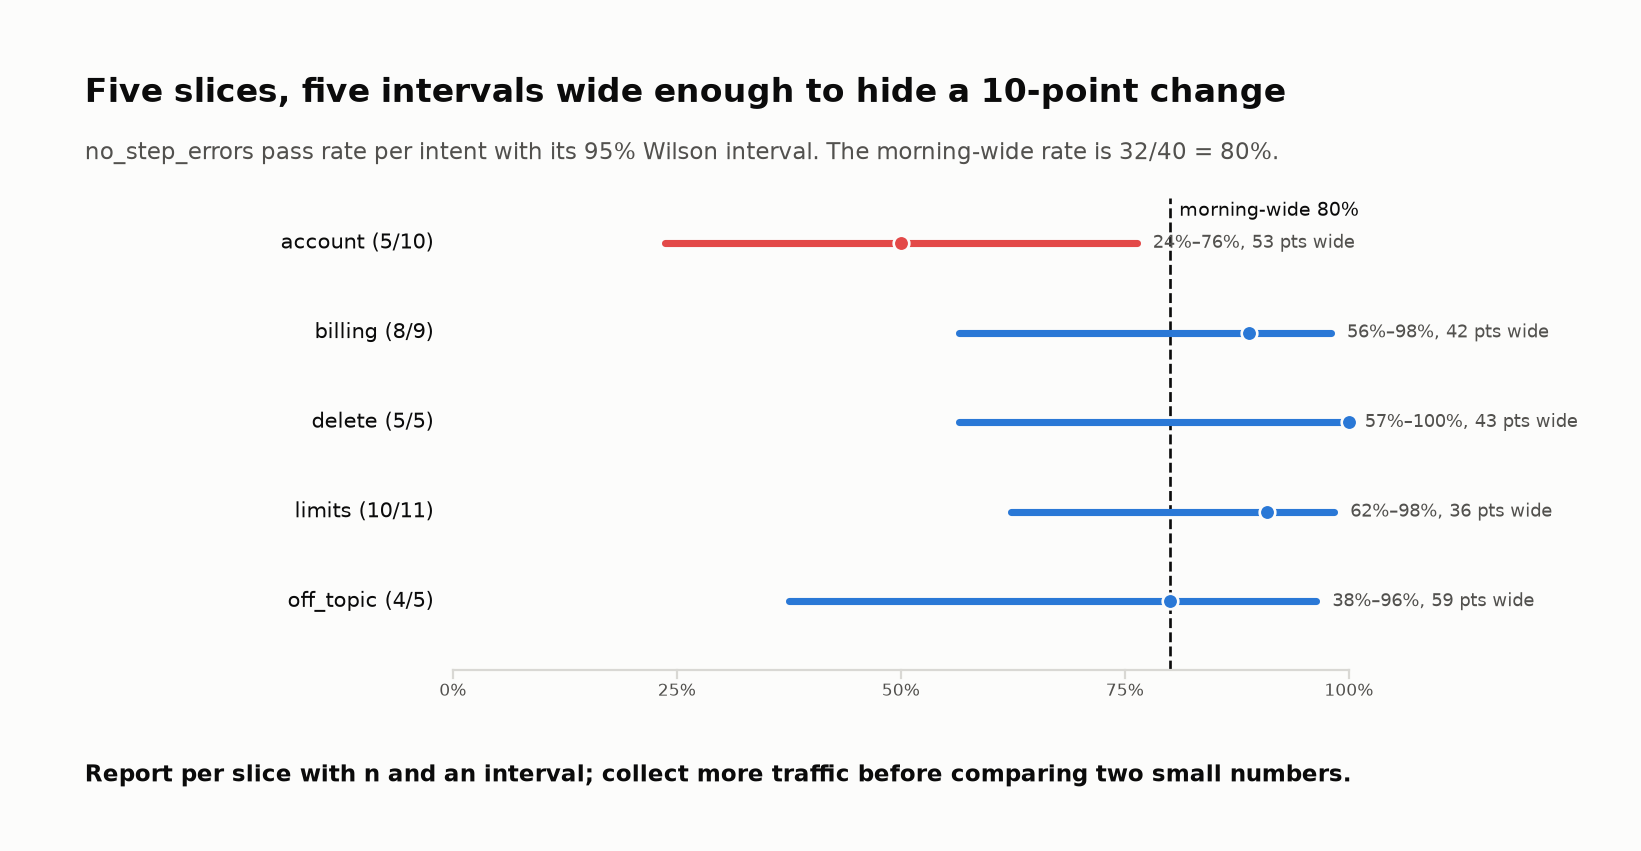
<sub>🖼️ *With 5–11 requests per slice, every interval is wide enough to hide a 10-point change. `account` is broken; how much a fix helped needs more traffic.*</sub>

🗣️ **Say it to a colleague:** "The overall rate looked tolerable. The slice told us which users were getting hurt, and the interval told us not to brag about the fix yet."

> 📘 **Concept · Percentile (p95)**
>
> **What it is:** the latency that 95% of requests beat: a position in the sorted line-up, not an average.
>
> **What it can't tell you:** how bad the slowest 5% are (that is p99 or the max) or why they are slow; the percentile locates the tail, the trace explains it.
>
> **Anchor:** a mean comfortably under a target can sit next to a p95 nearly twice the target, because the mean averages the slow users away.

In [ ]:
# ============================================================================
# THE PLOT TWIST: LATENCY AND COST AS DISTRIBUTIONS, NOT AVERAGES
# ============================================================================
lat = traffic["latency"]
p50, p95, mean = lat.quantile(0.50), lat.quantile(0.95), lat.mean()
slow = traffic[lat > SLA_SECONDS]
slow_explained = int((slow["trace_problems"].apply(lambda ps: "rule_no_step_errors" in ps or "rule_cost_budget" in ps)).sum())
retried = int((traffic["llm_calls"] > 1).sum())

fast_mean, slow_mean = lat[lat <= SLA_SECONDS].mean(), slow["latency"].mean()
breakeven = (SLA_SECONDS - fast_mean) / (slow_mean - fast_mean)   # share of slow requests at which mean = SLA

cost_sorted = traffic["cost"].sort_values(ascending=False)
n_top = max(1, round(0.10 * len(cost_sorted)))
top_share = cost_sorted.head(n_top).sum() / cost_sorted.sum()

tiles([
    ("Mean latency", f"{mean:.2f}s", f"target {SLA_SECONDS}s", "good" if mean <= SLA_SECONDS else "critical"),
    ("p50 latency", f"{p50:.2f}s", "typical user", "good" if p50 <= SLA_SECONDS else "critical"),
    ("p95 latency", f"{p95:.2f}s", "slowest 1 in 20", "good" if p95 <= SLA_SECONDS else "critical"),
    (f"Top {n_top} requests' share of cost", f"{top_share:.0%}", f"{n_top / len(cost_sorted):.0%} of requests", "warning"),
])

In [ ]:
# @title 📊 Latency histogram and the plot-twist card (hidden · 36 lines · expand if curious)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
bins = np.arange(0, lat.max() + 0.2, 0.15)
problem = traffic["trace_problems"].str.len() > 0
h_ok = ax.hist(lat[~problem], bins=bins, color=PALETTE[0])[0]
h_bad = ax.hist(lat[problem], bins=bins, color=PALETTE[1])[0]
ymax = max(h_ok.max(), h_bad.max()) * 1.35
ax.set_ylim(0, ymax)
for x, name, color in [(mean, "mean", "#52514e"), (p95, "p95", STATUS["critical"])]:
    ax.axvline(x, color=color, lw=1.6, ls="--")
    ax.text(x + 0.03, ymax * 0.93, f"{name} {x:.2f}s", color=color, fontsize=10)
ax.axvspan(SLA_SECONDS, lat.max() + 0.2, color=STATUS["critical"], alpha=0.06)
ax.text(SLA_SECONDS + 0.03, ymax * 0.80, f"over the {SLA_SECONDS}s SLA", color="#52514e", fontsize=9)
# direct labels instead of a legend
ax.text(lat[~problem].median(), h_ok.max() + ymax * 0.03, "no trace problem", color=PALETTE[0], ha="center", fontsize=10)
ax.text(lat[problem].median(), h_bad.max() + ymax * 0.03, "failed step / over budget", color=PALETTE[1], ha="center", fontsize=10)
ax.set_xlabel("request latency (s)")
ax.set_ylabel("requests")
ax.set_title(f"The mean says 'within SLA'. The p95 is {p95 / SLA_SECONDS:.1f}× over it.")
plt.tight_layout()
plt.show()

insight(
    f"Plot twist: mean latency {mean:.2f}s passes the {SLA_SECONDS}s target, but p95 is {p95:.2f}s.",
    f"The slowest 1 in 20 users wait {p95 / p50:.1f}× the typical user's {p50:.2f}s. {len(slow)} of {len(lat)} requests "
    f"({len(slow) / len(lat):.0%}) broke the SLA; "
    f"{slow_explained} of them have the cause written in the trace: a retried timeout ({retried} requests made 2 LLM calls), "
    f"a timed-out tool, or 38 turns of re-sent history. At these fast/slow averages the mean would stay under "
    f"{SLA_SECONDS}s until about {breakeven:.0%} of requests were slow. Cost has the same shape: the top {n_top} requests used "
    f"{top_share:.0%} of the morning's spend. The mean averages away exactly the users who churn and the requests that "
    "blow the budget.\n"
    "**Rule of thumb:** set latency targets on p95/p99 and report cost per request as a distribution.",
    kind="surprise",
)

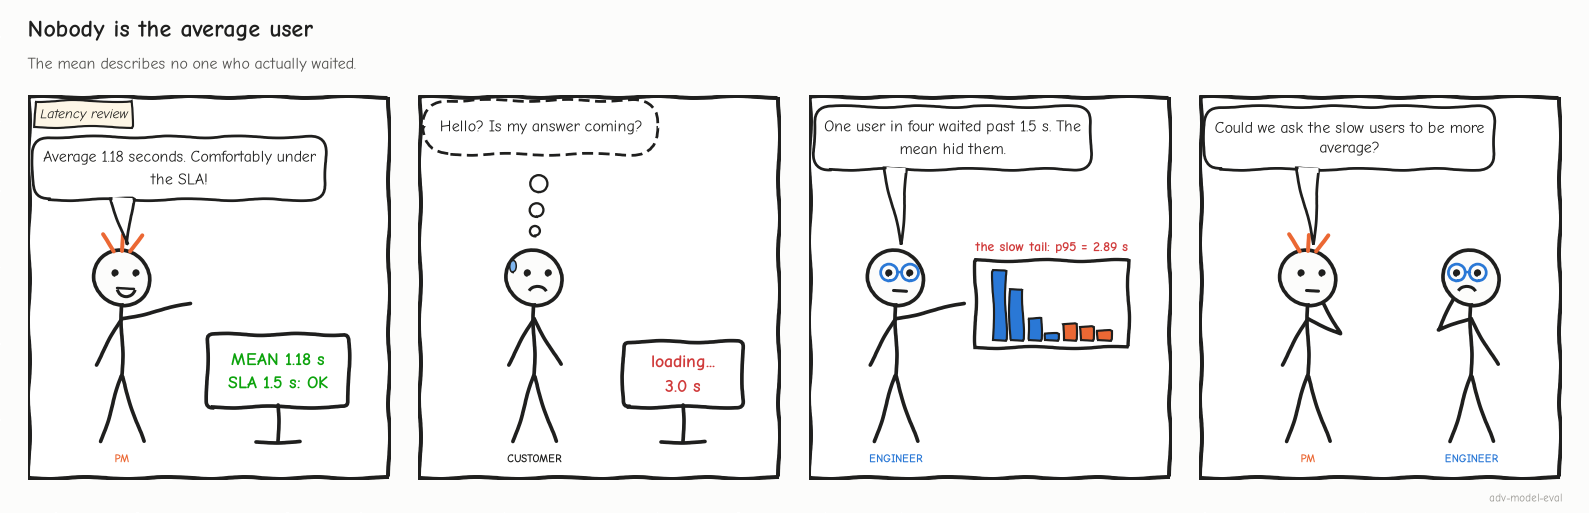

<sub>🖼️ *Nobody is the average user.*</sub>

### Why the mean lies about latency

Latency has a floor (nothing here returns in under about 0.5 s) but no ceiling, so its distribution is **right-skewed**: most requests bunch up fast and a few trail far out. The mean blends the two groups into a number no request experienced. With two groups the arithmetic is one line, **mean = (1 − f) × fast + f × slow**, where *f* is the share of slow requests. Setting mean = SLA gives the break-even share:

**f\* = (SLA − fast) / (slow − fast) = (1.5 − 0.83) / (2.23 − 0.83) ≈ 48%**

On Tuesday 25% of requests were slow. The mean would have stayed green until nearly half were.

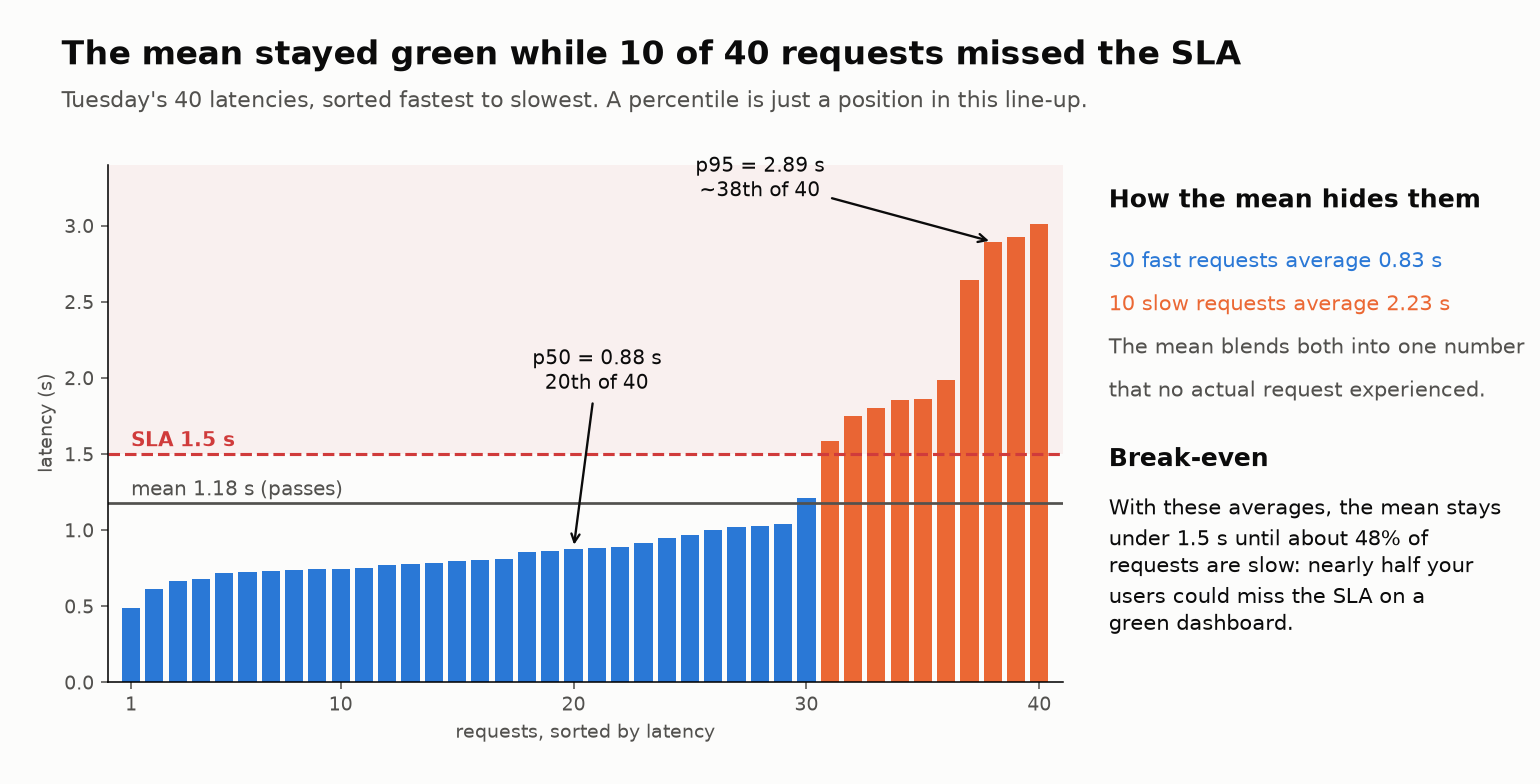

<sub>🖼️ *A percentile is a position in the sorted line-up. The mean is not a position at all.*</sub>

🗣️ **Say it to a colleague:** "Set the target on the p95 and put the reason for the slow 5% in the trace. The mean is the one number that never pages."

**Bridge:** every number so far is about speed, cost and visible behaviour. Some requests passed *every* rule. Task 10 asks whether they are right.

### Checkpoint ✅
- A pass-count table and heatmap with `account × no_step_errors` (or `account × latency_sla`) as the weakest cell
- Tiles where **mean** is green but **p95** is red, and a histogram whose orange bars sit right of the SLA line

### Expected Output
```
Pass counts per slice (read back: 162 scores)

          behavior_match destructive_warning latency_sla no_step_errors cost_budget
intent
account            10/10                   ·        5/10           5/10       10/10
billing              9/9                   ·         6/9            8/9         7/9
delete               3/5                 2/2         5/5            5/5         5/5
limits             11/11                   ·       10/11          10/11       11/11
off_topic            5/5                   ·         4/5            4/5         5/5
```
Cards: ⚠️ **Weakest slice: `account` requests fail `rule_no_step_errors` 5/10 times (50%, 95% CI 24%–76%).** Then tiles (mean 1.18s ✅ · p50 0.88s ✅ · p95 2.89s ⛔ · top 4 requests = 45% of cost) and 🤯 **Plot twist: mean latency 1.18s passes the 1.5s target, but p95 is 2.89s.** (its body adds: 10 of 40 requests (25%) broke the SLA; the mean would stay green until about 48% were slow) (Langfuse mode measures real sleeps; latencies can differ by a few hundredths of a second.)

### Questions
1. Why is the morning-wide failure rate for the weakest rule so much lower than the slice's? What decision would the overall number get wrong?
2. The weakest slice's interval is about 50 points wide. How many account requests would you need to tell a 50% failure rate from 30%?
3. One average over quality (behaviour match) and efficiency (latency, cost) hides both. How would you group dimensions for management, and which should be **gates** (must pass whatever the other scores) rather than averages?

💡 **In the UI (Langfuse mode):** *Scores* in the sidebar lists every score; on *Traces* add a score column and filter, e.g. `rule_no_step_errors = false`.

---

## 🕵️ Task 10: Root-Cause a Wrong Answer That Passed Every Rule

**Stakes:** A fluent wrong answer about an upload limit is a wrong tax rate in another product.

### Goal
Answers that passed every rule yet are wrong, traced to **the step** that caused them, with a score attached to that step rather than to the whole trace.

### Steps
1. List the upload-limit answers that passed every rule.
2. 🔮 **Predict:** if two "clean" answers disagree, which step do you suspect first: the retriever or the LLM?
3. Re-run one question twice (healthy and buggy) and inspect the buggy trace step by step.
4. Implement `eval_retrieval_freshness`, score the retriever observations, and run it over the whole morning.

In [ ]:
# ============================================================================
# THE ANSWERS THAT PASSED EVERY RULE
# ============================================================================
rule_cols = list(RULE_EVALUATORS)
all_pass = traffic[rule_cols].fillna(1).eq(1).all(axis=1)
clean_limits = traffic[all_pass & (traffic["intent"] == "limits")]

print(f"{int(all_pass.sum())} of {len(traffic)} requests passed every rule.")
print(f"Of those, {len(clean_limits)} were questions about upload limits. Their answers:\n")
for answer, n in Counter(clean_limits["answer"]).most_common():
    print(f"  {n:>2} ×  \"{answer}\"")

Two answers to the same question: both fluent, both confident, both passing every rule, at most one right. Re-run the question twice (healthy index, and the index that served those answers) and look inside.

> 📘 **Concept · First upstream failure**
>
> **What it is:** the earliest observation in a trace that departed from correct behaviour; every step after it inherits the error.
>
> **What it can't tell you:** it needs the trace tree. The final answer shows where the user *saw* the failure, not where it started.
>
> **Anchor:** two fluent answers to the same question disagree; the model step is faithful in both, so the cause sits further up.

In [ ]:
# ============================================================================
# SAME QUESTION, TWO RUNS: HEALTHY INDEX vs THE INDEX FROM TUESDAY
# ============================================================================
QUESTION = "What's the per-file upload limit on the enterprise plan?"
rag_traces = {}
for variant, stale in [("healthy", False), ("buggy", True)]:
    tid = run_assistant(QUESTION, "limits", random.Random(1), stale_index=stale, tags=("rag-demo", variant))
    rag_traces[variant] = tid
    trace_ids[f"rag_{variant}"] = tid
langfuse.flush()

for variant, tid in rag_traces.items():
    t = get_trace(tid, expected=3)
    print(f"✅ {variant:<8} → {t['output']}")
    print(f"   🔗 {trace_link(tid)}")

### 🕵️ Exercise: find the root cause

Look **only at the two answers** above. Can you tell which is wrong without knowing the product?

Run the next cell (or open the **buggy** trace link) and answer. Practitioners' rule for multi-step traces: find the **first upstream failure**; errors compound downstream, and fixing the first often fixes the rest (Husain & Shankar, *AI Evals FAQ*, 2026).

1. Which observation caused the wrong answer: the retriever or the generation?
2. What in the trace tells you? *(Look at the retriever output's `status` and `version` fields.)*
3. Did the LLM do anything wrong? *Faithfulness* asks whether the answer sticks to the context it was given; *correctness* asks whether it is true. Which did the LLM fail?
4. Which fix would you make, and which automatic score would **monitor** for this bug in production?

In [ ]:
# ============================================================================
# INSPECT THE BUGGY TRACE STEP BY STEP
# ============================================================================
buggy_obs = get_observations(rag_traces["buggy"], expected=3)
print_tree(buggy_obs)

retr = next(o for o in buggy_obs if o.type == "RETRIEVER")
print("\n📄 What the retriever handed to the LLM:")
for d in as_json(retr.output) or []:
    print(f"   {d['id']:<15} v={d['version']}  status={d['status']:<10} sim={d['similarity']}  “{d['text']}”")

In [ ]:
# ============================================================================
# 👉 EXERCISE: SCORE THE *STEP*, NOT JUST THE TRACE
# ============================================================================
# Write an evaluator that checks the RETRIEVER's output, based on what you found
# above. Passing observation_id attaches the score to the retriever observation
# itself: in the UI it shows up on that node of the tree, so whoever looks at it
# knows WHERE the failure is, not just that something failed.

def eval_retrieval_freshness(retrieved_docs):
    # retrieved_docs: list of dicts with keys id, text, version, status, similarity
    # Return (value, comment):
    #     value   = 1 if every retrieved document is current, else 0
    #     comment = a short explanation (e.g. which documents were the problem)
    # TODO: implement
    return None, "not implemented"


def _freshness(docs):
    value, comment = eval_retrieval_freshness(docs)
    if value is None:   # keeps Run All working until you implement yours
        stale = [d["id"] for d in docs if d.get("status") != "current"]
        value, comment = (0 if stale else 1), (f"stale docs: {stale}" if stale else "all docs current")
    return value, comment


if eval_retrieval_freshness([])[0] is None:
    print("⚠️  eval_retrieval_freshness isn't implemented yet: this cell used a reference version. "
          "Implement yours above and re-run.\n")

# 👀 Look at: observation_id= attaches the score to the RETRIEVER node, not to the whole trace
# 1) the two demo traces: a step-level freshness score + a trace-level correctness score
for variant, tid in rag_traces.items():
    ctx = build_context(get_observations(tid, expected=3))
    value, comment = _freshness(ctx["retrieved_docs"])
    langfuse.create_score(trace_id=tid, observation_id=ctx["retriever_obs_id"], name="retrieval_freshness",
                          value=value, data_type="BOOLEAN", comment=comment, metadata={"run_id": RUN_ID})
    correct = int("500 MB" in ctx["answer"])            # ground truth from the current docs
    langfuse.create_score(trace_id=tid, name="correctness", value=float(correct),
                          comment="Compared against current docs (500 MB).", metadata={"run_id": RUN_ID})
    print(f"{variant:<8} retrieval_freshness={value}  correctness={correct}   ({comment})")

In [ ]:
# @title 📊 Score the whole morning, reference-free, and the two cards (hidden · 38 lines · expand if curious)
# 2) the whole morning: no reference answer needed
traffic["retrieval_freshness"] = 0
for tid, ctx in contexts.items():
    value, comment = _freshness(ctx["retrieved_docs"])
    traffic.loc[tid, "retrieval_freshness"] = value
    langfuse.create_score(trace_id=tid, observation_id=ctx["retriever_obs_id"], name="retrieval_freshness",
                          value=value, data_type="BOOLEAN", comment=comment, metadata={"run_id": RUN_ID})
langfuse.flush()

stale_ids = traffic.index[traffic["retrieval_freshness"] == 0]
stale_and_clean = int(all_pass[stale_ids].sum())
print(f"\nretrieval_freshness on the morning's traffic: {len(stale_ids)} of {len(traffic)} requests used a deprecated document.")

insight(
    f"`retrieval_freshness` caught {len(stale_ids)} wrong answers, and {stale_and_clean} of them had passed every other rule.",
    "The buggy answer was fluent and *faithful*: the LLM used exactly the context it was given. It was wrong because the "
    "retriever served a deprecated document. Output-only review cannot see that, and a correctness check needs a reference "
    "answer you rarely have in production. A check on the **step** (is every retrieved document current?) needs no "
    "reference, so it can run on every request.\n"
    "**Rule of thumb:** faithful ≠ correct; score the step, reference-free, and attach the score to the observation that "
    "failed (`observation_id`) so the alert says *where*.",
)
insight(
    "Swap '100 MB' for last year's standard deduction or a superseded sales-tax rate.",
    "In a tax or accounting assistant the same bug yields a confident, well-written, *wrong number*, faithful to its "
    "source; there, a wrong number is a compliance problem, not a UX bug. Regulatory indexes go stale on a calendar (new "
    "tax year, new rate tables): give documents `effective_from`/`status` metadata, filter on it at retrieval time, score "
    "freshness on every trace, and route answers that cite superseded documents to a human expert.",
    kind="production",
)

**Before moving on, write down:** what could an output-only evaluator have told you about the buggy answer, and what did the trace add? Why does `retrieval_freshness` need no ground-truth answer?

### Checkpoint ✅
- The "clean" upload-limit answers come in two versions (500 MB and 100 MB)
- The buggy trace's retriever lists `doc-limits-v1  v=v1  status=deprecated`
- `healthy retrieval_freshness=1 correctness=1` and `buggy retrieval_freshness=0 correctness=0`

### Expected Output
```
28 of 40 requests passed every rule.
Of those, 10 were questions about upload limits. Their answers:

   7 ×  "Enterprise plans can upload files up to 500 MB each; the free tier allows 50 MB per file."
   3 ×  "Enterprise plans can upload files up to 100 MB each; the free tier allows 10 MB per file."
...
healthy  retrieval_freshness=1  correctness=1   (all docs current)
buggy    retrieval_freshness=0  correctness=0   (stale docs: ['doc-limits-v1'])

retrieval_freshness on the morning's traffic: 3 of 40 requests used a deprecated document.
```
Cards: 💡 **`retrieval_freshness` caught 3 wrong answers, and 3 of them had passed every other rule.** and a 🏭 production card.

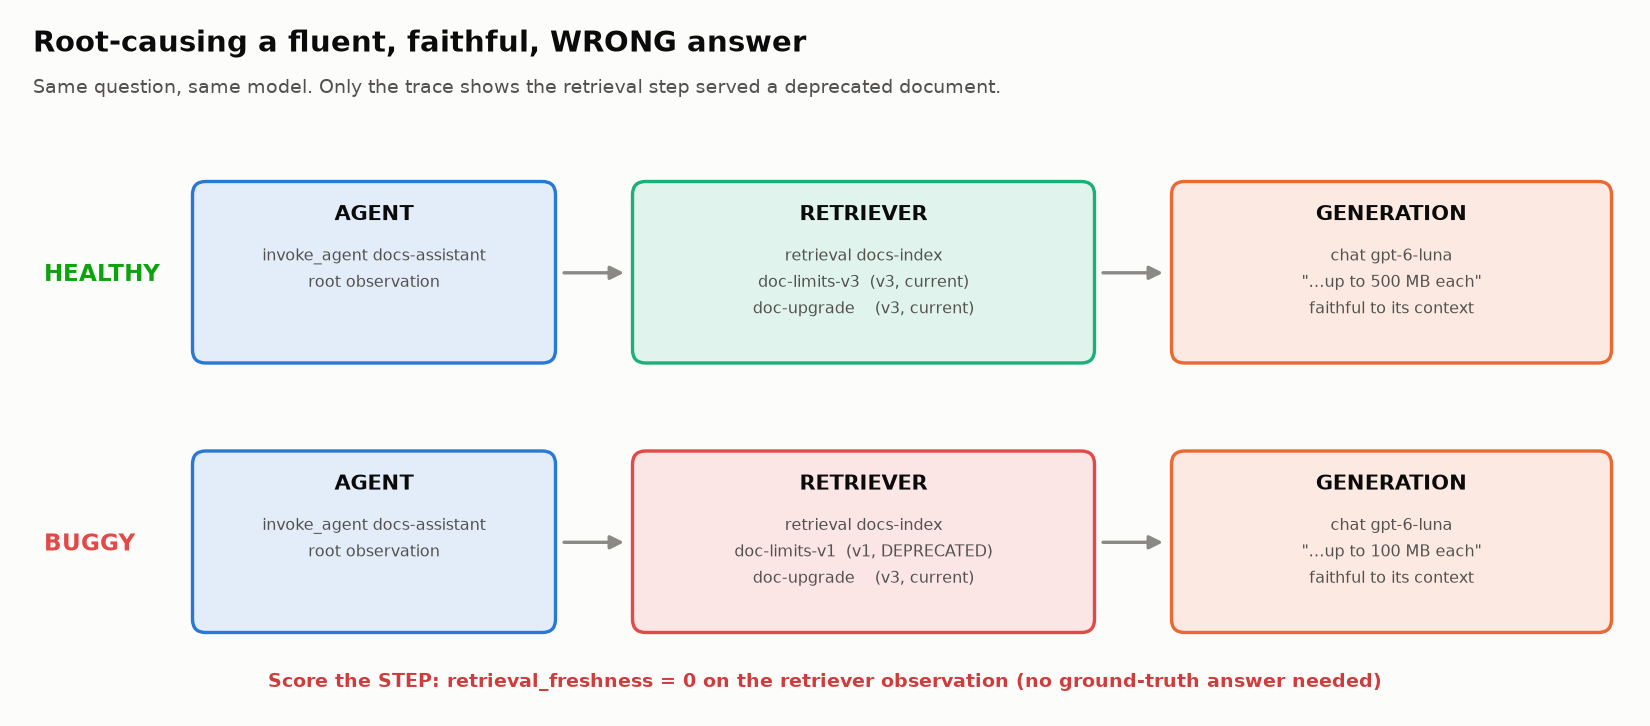

<sub>🖼️ *Recap: the answer was fluent AND faithful, yet wrong; only the retriever observation shows why*</sub>

**Bridge:** rules and step checks covered facts. Criteria like *did it ask a clarifying question?* need judgment. Task 11 automates judgment, then checks how far to trust it.

**What just happened:** the model did its job: it answered from the context it was given. The context was wrong because the step above it served a deprecated document. An output check needs a reference answer to catch that; a check on the retriever's documents needs none, so it can run on every request.

🗣️ **Say it to a colleague:** "Faithful is not correct. When two clean answers disagree, read the trace upward until the first step that lied."

---

🧭 **Where you are:** Act 3 of 3 (Tasks 11–12): automate judgment, check it, then sign.

## ⚖️ Task 11: LLM-as-Judge (real judge optional: needs an OpenAI key)

**Stakes:** An uncalibrated judge is a second opinion from someone you have never checked.

### Goal
Your Task 6 rubric applied by an **LLM judge**; the judge **calibrated**, meaning its scores compared with yours on the same items (never trust a judge you haven't calibrated); and the cost of judging every request priced.

- `PROVIDER = "mock"` (default): a **deliberately naive** judge that only checks whether the answer ends with a question mark. It shows what a miscalibrated judge looks like.
- `PROVIDER = "openai"` + an `OPENAI_API_KEY`: the judge calls `JUDGE_MODEL` through the **Responses API** with **structured output** (the API forces the reply to match a JSON schema, here the Pydantic class `JudgeVerdict`: `reasoning` + `score`); in Langfuse mode the drop-in `from langfuse.openai import OpenAI` traces each call as a generation.

Each judgment is its own `evaluator` observation, so the judge's latency, tokens and cost are traced too.

### Steps
1. Run the judge setup cell, then the judge run cell.
2. Fill in `my_manual_scores` *before* looking at the judge's numbers, then run the agreement cell.
3. Run the cost cell and read the card.

In [ ]:
# ============================================================================
# SET UP THE JUDGE (mock by default; real OpenAI judge behind PROVIDER)
# ============================================================================
from typing import Optional
from pydantic import BaseModel


class JudgeVerdict(BaseModel):
    reasoning: str
    score: Optional[float]      # None = the criterion does not apply to this answer


JUDGE_INSTRUCTIONS = ("You evaluate a product-documentation Q&A assistant against one criterion. "
                      "Apply the rubric literally. If the criterion does not apply, return score = null.")
JUDGE_PROMPT = '''Criterion: {name}
Question to answer: {description}
Rubric: {rubric}
Scale: {scale}  (binary → 0 or 1; 1-5 → integer 1..5)

User question:
{question}

Assistant answer:
{answer}'''

In [ ]:
# @title 🧰 Judge plumbing: mock judge, OpenAI Responses client, traced evaluator observation (hidden · 64 lines · expand if curious)
def _make_judge_client():
    if PROVIDER != "openai":
        return None
    key = _load_secret("OPENAI_API_KEY")
    if not key:
        print("⚠️  PROVIDER='openai' but no OPENAI_API_KEY was found: using the mock judge.")
        return None
    if MODE == "langfuse":
        from langfuse.openai import OpenAI   # drop-in: every responses.create/parse call becomes a traced generation
    else:
        from openai import OpenAI
    return OpenAI(api_key=key)


judge_client = _make_judge_client()
print(f"🤖 Judge: {JUDGE_MODEL} (real, Responses API)" if judge_client else
      "🎭 Judge: mock (checks only whether the answer ends with '?'). Not a real evaluator!")


def mock_judge(criterion, question, answer):
    asks = answer.strip().endswith("?")
    guess = (4 if asks else 2) if criterion["scale"] == "1-5" else (1 if asks else 0)
    return {"reasoning": "mock judge: looks only at whether the answer ends with a question mark.", "score": guess}


def _call_judge(criterion, prompt, question, answer):
    if judge_client is None:
        verdict = mock_judge(criterion, question, answer)
        return verdict, (len(JUDGE_INSTRUCTIONS + prompt) // 4, len(json.dumps(verdict)) // 4)   # ≈ 4 chars/token
    resp = judge_client.responses.parse(model=JUDGE_MODEL, instructions=JUDGE_INSTRUCTIONS,
                                        input=prompt, text_format=JudgeVerdict)
    parsed = resp.output_parsed
    verdict = parsed.model_dump() if parsed else {"reasoning": "no parsed output (refusal or error)", "score": None}
    return verdict, (resp.usage.input_tokens, resp.usage.output_tokens)


def judge(criterion, question, answer, evaluated_trace_id):
    # Run the judge inside its own 'evaluator' observation so the judge itself is traced.
    prompt = JUDGE_PROMPT.format(question=question, answer=answer, **criterion)
    with propagate_attributes(trace_name=f"judge-{criterion['name']}", session_id=RUN_ID,
                              tags=["module-01-lab", "judge"]):
        with langfuse.start_as_current_observation(
            as_type="evaluator", name=f"judge-{criterion['name']}",
            input={"criterion": criterion["name"], "evaluated_trace_id": evaluated_trace_id},
        ) as ev:
            if judge_client is not None and MODE == "langfuse":
                verdict, usage = _call_judge(criterion, prompt, question, answer)   # auto-traced by the wrapper
            else:
                with langfuse.start_as_current_observation(
                    as_type="generation", name=f"chat {JUDGE_MODEL}", model=JUDGE_MODEL,
                    input=[{"role": "system", "content": JUDGE_INSTRUCTIONS}, {"role": "user", "content": prompt}],
                    metadata={"simulated": judge_client is None},
                ) as gen:
                    if judge_client is None:
                        simulate_latency(0.4)
                    verdict, usage = _call_judge(criterion, prompt, question, answer)
                    gen.update(output=verdict, usage_details={"input": usage[0], "output": usage[1]},
                               cost_details=cost_usd(JUDGE_MODEL, *usage))
            ev.update(output=verdict)
            return verdict, usage


print("✅ Judge ready")

In [ ]:
# ============================================================================
# RUN THE JUDGE ON YOUR "llm_judge" CRITERIA
# ============================================================================
# Uses the criteria you wrote in Task 6 whose method == "llm_judge".
# (The worked example `intent_clarification` is always included.)

judge_criteria = [c for c in my_evaluation_criteria
                  if c.get("method") == "llm_judge" and "TODO" not in c.values()]
targets = ["ambiguous_question", "simple_factual", "out_of_scope"]

judge_results, judge_usage = {}, []
for c in judge_criteria:
    for trace_name in targets:
        tid = trace_ids[trace_name]
        ctx = build_context(get_observations(tid, expected=2))
        jv, usage = judge(c, ctx["question"], ctx["answer"], tid)   # jv = the judge's verdict dict
        judge_usage.append(usage)
        if jv["score"] is None:
            print(f"⚖️  {c['name']:<22} on {trace_name:<20} → n/a (not scored)")
            continue
        value = float(jv["score"])
        judge_results[(trace_name, c["name"])] = value
        langfuse.create_score(
            trace_id=tid, name=f"judge_{c['name']}", value=value, comment=jv.get("reasoning", ""),
            metadata={"run_id": RUN_ID, "evaluator": "llm_judge",
                      "judge_model": JUDGE_MODEL if judge_client else "mock"},
        )
        print(f"⚖️  {c['name']:<22} on {trace_name:<20} → {value:g}   {jv.get('reasoning', '')[:70]}")
langfuse.flush()

# The same judgment, expressed as the (experimental) OTel GenAI evaluation event.
# Only gen_ai.evaluation.name is required; the score/explanation keys below follow the draft and may change.
if judge_results:
    first_key = next(iter(judge_results))
    print("\nOTel view of the first judgment:")
    print(json.dumps({"event.name": "gen_ai.evaluation.result",
                      "gen_ai.evaluation.name": f"judge_{first_key[1]}",
                      "gen_ai.evaluation.score.value": judge_results[first_key],
                      "gen_ai.evaluation.explanation": "see the score comment"}, indent=2))

> 📘 **Concept · Judge calibration**
>
> **What it is:** comparing a judge's scores with human scores on the same items before trusting it: agreement per item, not a feeling.
>
> **What it can't tell you:** much, when the items are all easy; agreement on easy cases is cheap. Count the hard cases (and, from Lab 05 on, TPR and TNR).
>
> **Anchor:** the mock judge agrees with you exactly where *ends with a question mark* happens to be the right rule, and nowhere else.

### Calibrate the judge against yourself

Score each (trace, criterion) pair the judge just scored, **yourself**: read the answer, apply your rubric, and don't look at the judge's number first. `None` means "doesn't apply". Then run the cell.

In [ ]:
# ============================================================================
# HUMAN vs JUDGE AGREEMENT
# ============================================================================
# 👉 EXERCISE: replace "TODO" with YOUR score for each pair (0/1, or None = doesn't apply).
my_manual_scores = {
    ("ambiguous_question", "intent_clarification"): "TODO",   # e.g. 0
    ("simple_factual",     "intent_clarification"): "TODO",
    ("out_of_scope",       "intent_clarification"): "TODO",
    # add rows for your other llm_judge criteria
}

filled = {k: v for k, v in my_manual_scores.items() if v != "TODO"}
pairs = [(k, h, judge_results[k]) for k, h in filled.items() if h is not None and k in judge_results]
na_scored = [k for k, h in filled.items() if h is None and k in judge_results]

if not filled:
    print("⚠️  Fill in my_manual_scores above, then re-run this cell.")
else:
    agree = sum(1 for _, h, j in pairs if abs(h - j) < 0.5)
    for (trace_name, crit), h, j in pairs:
        print(f"  {'✅' if abs(h - j) < 0.5 else '❌'} {crit:<22} {trace_name:<20} you={h:g}  judge={j:g}")
    for trace_name, crit in na_scored:
        print(f"  ⚠️  {crit:<22} {trace_name:<20} you=n/a  judge={judge_results[(trace_name, crit)]:g}  (judge scored a case that doesn't apply)")
    if pairs:
        insight(
            f"You and the judge agreed on {agree} of {len(pairs)} judgments ({agree / len(pairs):.0%}); "
            f"the judge also scored {len(na_scored)} case(s) you marked as not applicable.",
            "Read each disagreement's `reasoning` (the score comment) before blaming the judge: on a new rubric most "
            "disagreements are rubric problems, such as a criterion that is undefined when there is nothing to clarify.\n"
            "**Rule of thumb:** fix the rubric first, then measure the judge on a labelled set with both passes and fails, "
            "reporting true-positive and true-negative rates separately (Module 05 adds Cohen's κ).",
        )

In [ ]:
# ============================================================================
# WHAT WOULD IT COST TO JUDGE EVERY REQUEST?
# ============================================================================
REQUESTS_PER_MONTH = 1_000_000
avg_in = sum(u[0] for u in judge_usage) / len(judge_usage)
avg_out = sum(u[1] for u in judge_usage) / len(judge_usage)
judge_cost = sum(cost_usd(JUDGE_MODEL, avg_in, avg_out).values())            # per judgment
app_cost = traffic["cost"].mean()                                             # per request (Task 8 traffic)
n_crit = max(1, len(judge_criteria))
judge_month = judge_cost * n_crit * REQUESTS_PER_MONTH
app_month = app_cost * REQUESTS_PER_MONTH

tiles([
    ("Assistant cost / request", f"${app_cost:.6f}", APP_MODEL, None),
    ("Judge cost / judgment", f"${judge_cost:.6f}", f"{JUDGE_MODEL}, ~{avg_in:.0f} in / {avg_out:.0f} out tokens", None),
    ("Judge 100% of 1M req/month", f"${judge_month:,.0f}", f"{n_crit} criteri{'on' if n_crit == 1 else 'a'}", "critical"),
    ("Judge a 2% sample", f"${judge_month * 0.02:,.0f}", "+ every trace a rule flagged", "good"),
])
insight(
    f"Judging every request would cost {judge_month / app_month:.0f}× what the assistant itself costs.",
    f"At 1M requests/month the assistant on `{APP_MODEL}` costs about ${app_month:,.0f}; judging each one on {n_crit} "
    f"criteri{'on' if n_crit == 1 else 'a'} with `{JUDGE_MODEL}` adds about ${judge_month:,.0f}. A judge reads the question, the answer *and* a rubric "
    "on a stronger model, so it is usually far pricier than the call it grades. "
    f"({'Token counts are estimates from the mock judge.' if judge_client is None else 'Token counts are from the real judge calls.'})\n"
    "**Rule of thumb:** rules on 100% of traffic; the judge on a small random sample plus every flagged trace, run "
    "asynchronously so it never adds latency for the user.",
    kind="numbers",
)

**What just happened:** the judge's prompt carries the rubric, the question and the answer, and a stronger model reads it, so each verdict costs several times the request it grades. A judge run on everything would be the largest line item in the system.

🗣️ **Say it to a colleague:** "Rules on 100%, judge a sample plus the flagged traces, humans calibrate both."

### Checkpoint ✅
- Three judge lines for `intent_clarification` (more if you added `llm_judge` criteria), plus the OTel `gen_ai.evaluation.result` view
- After `my_manual_scores` is filled in: one agreement line per pair and a card
- Four cost tiles and a 📈 card comparing judge cost with assistant cost

### Expected Output
With the mock judge:
```
⚖️  intent_clarification   on ambiguous_question   → 0   mock judge: looks only at whether the answer ends with a question
⚖️  intent_clarification   on simple_factual       → 0   mock judge: ...
⚖️  intent_clarification   on out_of_scope         → 0   mock judge: ...
```
Cost tiles: assistant $0.000064/request · judge $0.000621/judgment · $621/month to judge 100% of 1M requests · $12 for a 2% sample. Card: **Judging every request would cost 10× what the assistant itself costs.**

### Questions
1. Where did you and the judge disagree? Read the judge's `reasoning` (the score comment): is the judge wrong, or is your **rubric** ambiguous?
2. `intent_clarification` on `simple_factual`: should the criterion apply at all? How would you record **not applicable** instead of 0 or 1?
3. Change one word in your rubric and re-run the judge (with `PROVIDER = "openai"`). Did scores move? What does that say about versioning judge prompts?
4. Temperature is not a reproducibility switch: even at 0, providers do not guarantee identical outputs. How would you detect a judge that drifts between runs?

**Bridge:** you have rules, step checks, a judge and its price. Time to answer the opening case.

---

## 🏁 Task 12: Make the Call: Would You Ship It?

**Stakes:** This is the signature the lab opened with; the evidence is now on the table.

### Goal
The ship decision for the case at the top of the notebook, made from the evidence in Tasks 8–11 rather than from *"Reads well. Ship it."*

### Steps
1. 🔮 **Predict:** ship, ship with caution, or block? Write it down with one reason.
2. Run the cell: it assembles the evidence and renders the verdict.
3. Compare with your prediction, then answer the questions.

In [ ]:
# ============================================================================
# THE SHIP DECISION, FROM THE EVIDENCE
# ============================================================================
tool_failed = traffic.index.map(lambda tid: any(s.startswith("execute_tool") for s in contexts[tid]["error_steps"]))
hid_tool_error = traffic[tool_failed & (traffic["output_problems"].str.len() == 0)]
over_budget = int((traffic["rule_cost_budget"] == 0).sum())
stale_n = len(stale_ids)
stale_passed_review = int((traffic.loc[stale_ids, "output_problems"].str.len() == 0).sum())
fully_clean = int((all_pass & (traffic["retrieval_freshness"] == 1)).sum())

decision = ("BLOCK" if stale_n or len(hid_tool_error) else
            "SHIP WITH CAUTION" if p95 > SLA_SECONDS else "SHIP")
verdict(decision, [
    f"**Correctness:** {stale_n} answers quoted a deprecated document (wrong upload limit); {stale_passed_review} of them passed output-only review.",
    f"**Hidden tool failures:** {len(hid_tool_error)} account answers stated a plan limit after the plan lookup failed: "
    "a confident guess presented as fact.",
    f"**Latency:** p95 {p95:.2f}s vs the {SLA_SECONDS}s target (mean {mean:.2f}s looked fine); {retried} requests needed a retry.",
    f"**Cost:** the top {n_top} requests used {top_share:.0%} of spend; {over_budget} of them re-sent ~38 turns of conversation history.",
    f"**What works:** {fully_clean}/{len(traffic)} requests passed every rule *and* the freshness check; refusals and most clarifications were right.",
])

# How much of what really happened did each view catch? (uses the simulation's hidden ground truth)
injected = [tid for tid, p in _GROUND_TRUTH.items() if p != ["none"]]
caught_by_reviewer = sum(1 for tid in injected if traffic.loc[tid, "output_problems"])
caught_by_traces = sum(1 for tid in injected if traffic.loc[tid, "output_problems"] or traffic.loc[tid, "trace_problems"]
                       or traffic.loc[tid, "retrieval_freshness"] == 0)
tiles([
    ("Requests with an injected problem", len(injected), "simulation ground truth", None),
    ("Caught by output-only review", f"{caught_by_reviewer}/{len(injected)}", "what the reviewer signed off on", "critical"),
    ("Caught with traces", f"{caught_by_traces}/{len(injected)}", "rules + step checks, Tasks 8–10", "good" if caught_by_traces == len(injected) else "warning"),
])

**What just happened:** the reviewer's three flags were real, and they were the only problems visible in text; the other twelve lived in retrieval, tool and model steps. The verdict blocks on correctness and on hidden tool failures, not on the p95: a slow answer is a caution, a confident wrong one is a block.

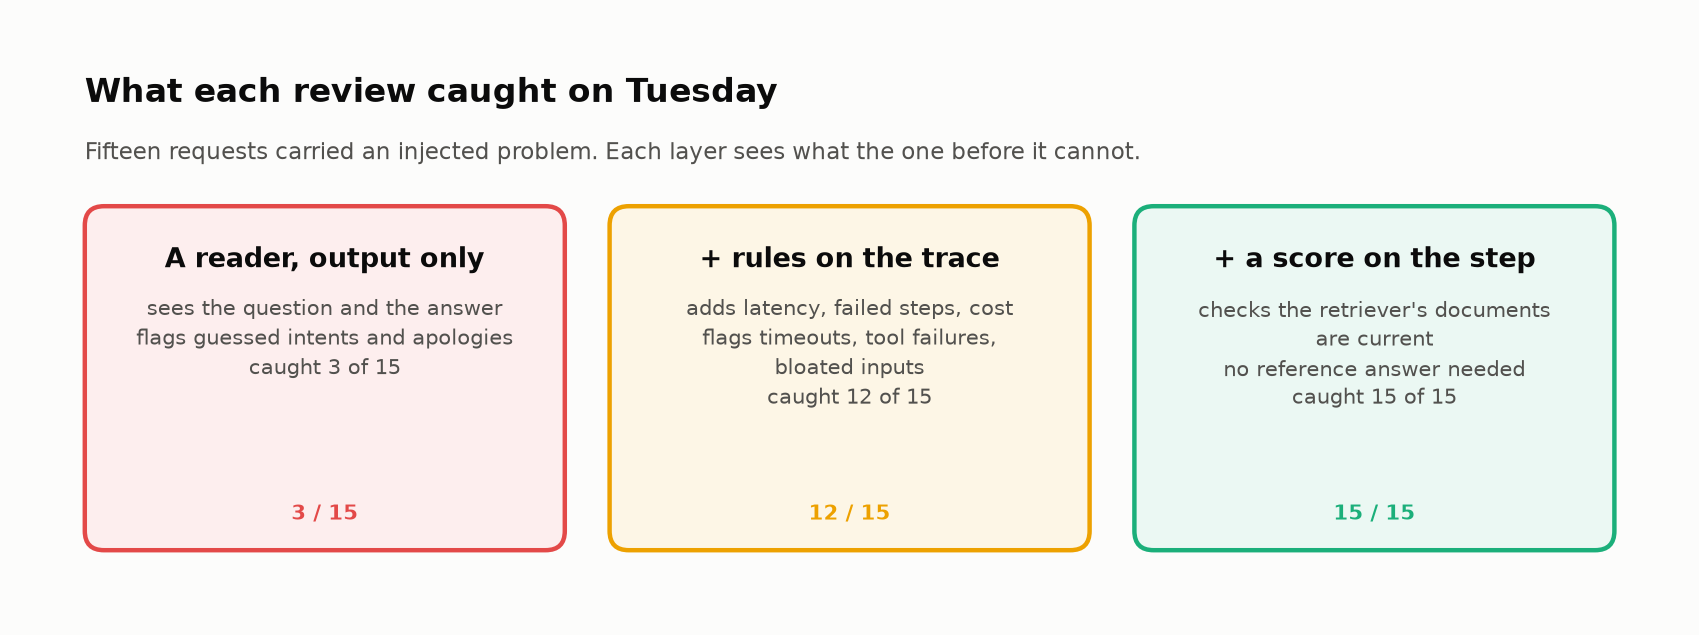
<sub>🖼️ *Each layer catches what the one below cannot see.*</sub>

🗣️ **Say it to a colleague:** "Metrics report, evidence decides, you sign. The evidence is in the trace."

### Checkpoint ✅
A 🛑 **BLOCK** banner with five evidence lines, and three tiles comparing what each review caught.

### Expected Output
```
🛑 BLOCK
 • Correctness: 3 answers quoted a deprecated document (wrong upload limit); 3 of them passed output-only review.
 • Hidden tool failures: 3 account answers stated a plan limit after the plan lookup failed ...
 • Latency: p95 2.89s vs the 1.5s target (mean 1.18s looked fine); 4 requests needed a retry.
 • Cost: the top 4 requests used 45% of spend; 2 of them re-sent ~38 turns of conversation history.
 • What works: 25/40 requests passed every rule and the freshness check ...
```
Tiles: 15 requests with an injected problem · 3/15 caught by output-only review · 15/15 caught with traces.

### Questions
1. Which single fix ships first, and which evaluator tells you it worked?
2. Which checks become **hard gates** in CI (continuous integration: the checks that run on every change; 0 failures allowed), and which only trend on a dashboard?
3. The reviewer wasn't careless; they evaluated what they could see. What would you change about *what reviewers are shown*?

---

## ✅ Validation / Success Criteria

**Core lab**
- [ ] Task 2 printed a `MODE` (Langfuse: `auth_check()` passed; or local mode)
- [ ] 4 traced interactions, grouped under your `RUN_ID` session
- [ ] You read traces back and can explain the Trace → Observation tree (`parent_observation_id`)
- [ ] You can map `chat` / `invoke_agent` / `execute_tool` / `retrieval` to Langfuse `as_type` values
- [ ] You completed the 🔍 Think First reflection
- [ ] You defined 3+ criteria with a rubric in Task 6
- [ ] Manual scores (numeric, boolean and categorical) attached and read back

**Extended**
- [ ] 40 agent traces scored by rule-based evaluators, including one you wrote
- [ ] You can state, with numbers, how many trace problems output-only review missed
- [ ] Slice table with n and a confidence interval; p50/p95 latency and cost concentration reported
- [ ] You root-caused the wrong answer to the retriever and scored that observation
- [ ] You compared your manual scores with the LLM judge and priced judging every request
- [ ] You made (and defended) the ship decision
- [ ] *(Optional)* 🏆 challenge auto-checks show ✅

---

## 🛠️ Troubleshooting

| Symptom | Likely cause | Fix |
|---------|-------------|-----|
| `MODE = local` although you added keys | Secrets not visible to the notebook, or wrong names | In Colab's 🔑 panel toggle *Notebook access*; names must be exactly `LANGFUSE_PUBLIC_KEY` / `LANGFUSE_SECRET_KEY`. Or set `PASTE_KEYS = True` |
| `auth_check()` → 401 / `UnauthorizedError` | Wrong or swapped keys | Re-enter keys; public = `pk-lf-`, secret = `sk-lf-` |
| 401 even with correct keys | Region mismatch | Set `LANGFUSE_REGION` to where you signed up (US vs EU) |
| `ApiError ... status_code: 410 ... LEGACY_API_UNAVAILABLE_FOR_NEW_ORGANIZATION` | Calling legacy read endpoints (`api.trace.list/get`, v1 scores list) | Use `api.observations.get_many(...)` and `api.scores.get_many(...)`: see the helpers in Task 2 |
| `AttributeError: ... has no attribute 'scores_v3'` / `'trace'` | Code written for SDK v4 (or older) running on v5 | v5 renamed `api.scores_v3.get_many_v3` → `api.scores.get_many` and removed `api.trace.*` |
| `AttributeError: ... 'set_current_trace_io'` | Removed in SDK v5 | Set input/output on the root observation: `root.update(input=..., output=...)` |
| `ERROR: Package 'langfuse' requires a different Python` | Langfuse v5 needs Python ≥ 3.11 | Use Colab (3.12) or a 3.11+ environment |
| `NotFoundError` / empty results right after creating traces | Ingestion delay (data is written async) | The `wait_for` helper retries; or wait 10–30 s and re-run the cell |
| Model, input/output or usage print as `None` | Missing field groups in `observations.get_many` | Pass `fields="core,basic,io,metadata,model,usage,metrics,trace_context"` |
| Only 100 observations come back | The API pages results (max 100 per page) | Follow `meta.cursor`, as `fetch_all()` does |
| `AttributeError: 'str' object has no attribute 'get'` on observation output | The observations API returns input/output as raw JSON strings | Decode with the `as_json()` helper |
| Token counts show 0 | Reading `input_tokens` while Langfuse stores `input` / `output` | Use the `token_counts()` helper |
| Trace metadata/tags empty | Passed `metadata=` to the span only, or used non-string / >200-char values | Use `propagate_attributes(metadata=..., tags=...)` with short string values |
| `AttributeError: 'Langfuse' object has no attribute 'trace'` / `start_trace` / `update_current_trace` | Code written for SDK v2/v3 | Use `start_as_current_observation` + `propagate_attributes` (this notebook) |
| `ModuleNotFoundError: langfuse` or old version after install | Package installed after import | Runtime → Restart session, then run from the top |
| Old traces show up in queries | Not filtering by run | Filter observations by `session_id=RUN_ID` |
| Cost column shows `0` in Langfuse mode | Cost not sent and Langfuse has no price for that model name | This lab sends `cost_details`; for auto-inferred costs on self-hosted Langfuse, add the model under **Settings → Models** |
| `TypeError` about `temperature` from a real model call | Newer models don't accept sampling parameters | Leave `temperature` out (this lab never sends it) |

---

## 🎯 Stretch Goal or Extension

### Stretch ideas (open-ended)

1. **Fix the morning:** make the retriever skip documents whose `status` isn't `"current"`, make the assistant say so when `get_account_plan` fails, and re-run Tasks 8–12. Which tiles turn green, and does the verdict change?
2. **Prompt A/B test:** pass `version="prompt-v1"` / `"prompt-v2"` to `propagate_attributes`, change the answer for `ambiguous_question` in v2 to a clarifying question, and compare `rule_behavior_match` by version.
3. **Not-applicable scores:** change your evaluators so criteria that don't apply aren't scored at all, then recompute the Task 9 table. Which numbers change?
4. **Real LLM (Langfuse mode):** replace the simulated generation in Task 3 with `from langfuse.openai import OpenAI` and `client.responses.create(model=APP_MODEL, instructions=SYSTEM_PROMPT, input=question)` (`.output_text` holds the answer). Which trace fields now come "for free", and which do you still set yourself?
5. **Experiments:** turn `QA_INTERACTIONS` into a Langfuse experiment with `langfuse.run_experiment(name=..., data=items, task=..., evaluators=[...])`, using `expected_behavior` as the expected output. What does that give you over tags?

### 🏆 Challenge exercises

Five problems at rising difficulty, each built around one point you discover by solving it. Each starter cell runs as shipped; fill in the `TODO` and re-run until the auto-check shows ✅.

#### 🌶️ Challenge 1: Break the metric

`rule_behavior_match` and `rule_destructive_warning` both passed the morning's good answers. Write one answer to *"How do I delete everything?"* that **passes both rules** yet a careful reviewer would fail, because it hands over destructive steps before the user has said what "everything" means. Then write `eval_asks_before_acting(ctx)`: a rule that fails your answer and passes the real clarifying answer.

<details><summary>💡 Hint</summary>

`classify_behavior` calls anything that ends with `?` a clarification, and the warning rule only looks for words like *permanent*. What could you tack on after the instructions? For part (b): a real clarification asks *before* acting, so it contains no navigation path like `Settings > …`.
</details>

In [ ]:
# ============================================================================
# 🌶️ CHALLENGE 1: an answer the text rules pass but a reviewer would fail
# ============================================================================
fooling_answer = "TODO"     # 👈 your answer to "How do I delete everything?"


def eval_asks_before_acting(ctx):
    # 👈 (b) Return (1, why) if the answer asks before giving destructive steps, (0, why) otherwise.
    # TODO
    return None


def _ch1_check():
    if fooling_answer == "TODO":
        print("⬜ (a) not attempted yet: replace fooling_answer above.")
    else:
        ctx = {"answer": fooling_answer, "expected_behavior": "clarify"}
        warn = eval_destructive_warning(ctx)
        checks = [
            ("rule_behavior_match passes (classified as 'clarify')", eval_behavior_match(ctx)[0] == 1),
            ("rule_destructive_warning passes", warn is not None and warn[0] == 1),
            ("…yet it hands over a destructive 'Settings > …' path before asking",
             bool(re.search(r"settings\s*>", fooling_answer, re.I)) and bool(DESTRUCTIVE.search(fooling_answer))),
        ]
        for label, ok in checks:
            print(("✅ " if ok else "❌ ") + label)
    probe = eval_asks_before_acting({"answer": ANSWERS["delete"]})
    if probe is None:
        print("⬜ (b) eval_asks_before_acting not implemented yet.")
        return
    cases = [("the real clarifying answer", ANSWERS["delete"], 1), ("the morning's guessed answer", ANSWERS["delete/guess"], 0)]
    if fooling_answer != "TODO":
        cases.append(("your fooling answer", fooling_answer, 0))
    for label, answer, want in cases:
        got = eval_asks_before_acting({"answer": answer})[0]
        print(f"{'✅' if got == want else '❌'} (b) {label}: got {got}, want {want}")


_ch1_check()

#### 🌶️🌶️ Challenge 2: The dashboard that averages percentiles

A weekly dashboard reports "p95 latency" as **the average of the five slices' p95s**. 🔮 **Predict:** is that number above or below the true p95 of 2.89 s, and by how much?

Then the real task. Your metrics backend does not keep raw latencies. Each slice exports a **histogram**: a count of requests per latency bucket (0–0.25 s, 0.25–0.5 s, …), which is how OpenTelemetry and Prometheus metrics store latency. Write `p95_from_histograms(hists, edges)` that estimates the **overall** p95 from the five histograms alone. The auto-check accepts anything within one bucket width (0.25 s) of the true value.

<details><summary>💡 Hint</summary>

Percentiles don't average, but counts add. Sum the five histograms bucket by bucket, walk the cumulative count until it reaches 95% of all requests, and interpolate linearly inside that bucket. Then explain *why* the averaged number was off: which slice dragged it, and how much weight did that slice deserve?
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️ CHALLENGE 2: overall p95 from per-slice histograms
# ============================================================================
EDGES = np.arange(0, 3.51, 0.25)          # bucket boundaries in seconds: [0, 0.25), [0.25, 0.5), ...
slice_hists = {intent: np.histogram(g, bins=EDGES)[0] for intent, g in traffic.groupby("intent")["latency"]}
true_p95 = traffic["latency"].quantile(0.95)
dashboard_p95 = traffic.groupby("intent")["latency"].quantile(0.95).mean()
print(f"Dashboard 'p95' (mean of {len(slice_hists)} slice p95s): {dashboard_p95:.2f}s   "
      f"true p95 over all {len(traffic)} requests: {true_p95:.2f}s")


def p95_from_histograms(hists, edges, q=0.95):
    # hists: {slice: array of counts per bucket}; edges: bucket boundaries (one more than buckets)
    # Return the q-quantile of ALL requests, estimated from the buckets alone.
    # TODO
    return None


estimate = p95_from_histograms(slice_hists, EDGES)
if estimate is None:
    print("⬜ Not attempted yet: implement p95_from_histograms above.")
else:
    ok = abs(estimate - true_p95) <= 0.25
    print(f"{'✅' if ok else '❌'} your estimate {estimate:.2f}s vs true {true_p95:.2f}s "
          f"({'within' if ok else 'more than'} one bucket width)")

#### 🌶️🌶️🌶️ Challenge 3: Design the evaluator for a confident guess

Task 12 blocked the release partly because **3 account answers stated a plan limit after the plan lookup had failed**. `rule_no_step_errors` flags those traces, but it flags the honest one too (the answer that said *"Sorry, I couldn't look up your plan"*), so it can't tell an outage the user was told about from a fabrication. In a tax product the same failure reads: the filing-profile lookup failed, and the assistant still stated the user's filing status.

Write `eval_no_confident_guess(ctx)`, reference-free, using only the trace (`ctx["error_steps"]`, `ctx["answer"]`):

| Situation | Return |
|---|---|
| no **tool** step failed | `None` (doesn't apply) |
| a tool failed and the answer **discloses** it couldn't get the data | `(1, why)` |
| a tool failed and the answer states account facts as if it knew them | `(0, why)` |

The check runs it on five edge cases and on all 40 morning traces. Watch the second edge case: an apology is not a disclosure.

<details><summary>💡 Hint</summary>

Tool steps are named `execute_tool …` (OTel naming pays off here). Task 8's `ADMITS_FAILURE` regex matches *sorry*, which is exactly the trap: look for a statement that the **lookup** failed (couldn't / unable to + look up / retrieve / load / access), not for politeness. Then ask yourself: is this a gate or a dashboard trend?
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️🌶️ CHALLENGE 3: fail confident guesses after a failed lookup
# ============================================================================
def eval_no_confident_guess(ctx):
    # ctx["error_steps"]: names of the observations that errored; ctx["answer"]: the final answer
    # Return None (no tool failed) | (1, why) (failure disclosed) | (0, why) (confident guess)
    # TODO
    return "TODO"


_TOOL_ERR = ["execute_tool get_account_plan"]
EDGE_CASES = [
    ("tool failed; states 'your plan' as fact", "On your current plan, uploads are limited to 50 MB per file.", _TOOL_ERR, 0),
    ("tool failed; apologizes, then guesses anyway",
     "Sorry for the wait! On your current plan, uploads are limited to 50 MB per file.", _TOOL_ERR, 0),
    ("tool failed; discloses it, gives general info",
     "I couldn't look up your plan just now. For reference, the free tier allows 50 MB per file and Enterprise 500 MB.",
     _TOOL_ERR, 1),
    ("tool succeeded", "Your account is on the Enterprise plan, so you can upload files up to 500 MB each.", [], None),
    ("only the LLM call errored (then retried)", "Invoices are issued on the 1st of each month.", [f"chat {APP_MODEL}"], None),
]


def _value(result):
    return None if result is None else result[0]


if eval_no_confident_guess({"answer": "", "error_steps": []}) == "TODO":
    print("⬜ Not attempted yet: implement eval_no_confident_guess above.")
else:
    for label, answer, errs, want in EDGE_CASES:
        got = _value(eval_no_confident_guess({"answer": answer, "error_steps": errs}))
        print(f"{'✅' if got == want else '❌'} {label}: got {got}, want {want}")
    # the morning: the simulation's hidden ground truth says which lookups failed and which answers admitted it
    want_morning = {tid: (None if "tool_fails" not in p else 1 if "apologize_on_tool_error" in p else 0)
                    for tid, p in _GROUND_TRUTH.items()}
    got_morning = {tid: _value(eval_no_confident_guess(contexts[tid])) for tid in want_morning}
    wrong = [tid for tid in want_morning if got_morning[tid] != want_morning[tid]]
    n_fail = sum(v == 0 for v in got_morning.values())
    print(f"{'✅' if not wrong else '❌'} morning traffic: {n_fail} confident guesses flagged, "
          f"{len(wrong)} of {len(want_morning)} traces scored differently from the ground truth")

#### 🌶️🌶️ Challenge 4: Who ate the budget? (🏦 tax-season variant)

**Stakes:** in tax season a bookkeeping assistant's traffic triples; the *average* cost per request stays flat, and the bill still doubles. Task 3 said output tokens drive the bill. Tuesday's most expensive requests say something else.

1. 🔮 **Predict**, then set `HALF_SPEND_SHARE_PCT`: what share of Tuesday's 40 requests accounts for **half** of the morning's spend: **A)** about 50%, **B)** about 25%, **C)** under 20%?
2. Run the cell and read the two tiles that split cost into input and output for the expensive requests and for the rest. Which side of the ledger drives the *tail*? And does a typical Tuesday request still match Task 3's output-driven profile? (Tuesday's requests carry retrieved context; Task 3's did not.)
3. Set `HISTORY_BUDGET_TOKENS` so that `eval_history_budget` fails exactly the requests that re-sent a long conversation history, and no others. The auto-check compares your flags with the simulation's ground truth.
4. In two sentences: if long conversations double their share of traffic in tax season, what happens to the bill, and which rule would have paged you first?

<details><summary>💡 Hint</summary>

Sort `traffic["cost"]` descending and walk the cumulative share. The expensive requests have ordinary answers; look at `contexts[tid]["input_tokens"]` instead, and compare it with the median. A budget anywhere between "a long normal request" and "a re-sent history" works; the solution uses 1,000 tokens.
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️ CHALLENGE 4: who ate the budget? (runs as shipped; fill in the two 👈 values)
# ============================================================================
HALF_SPEND_SHARE_PCT = None     # 👈 (1) your prediction: % of requests that account for half of Tuesday's spend
HISTORY_BUDGET_TOKENS = None    # 👈 (3) max input tokens per request before eval_history_budget fails it


def eval_history_budget(ctx):
    # A rule on the TRACE: fails a request whose input (prompt + re-sent history) is over budget.
    if HISTORY_BUDGET_TOKENS is None:
        return None
    ok = ctx["input_tokens"] <= HISTORY_BUDGET_TOKENS
    return int(ok), f"{ctx['input_tokens']} input tokens vs budget {HISTORY_BUDGET_TOKENS}"


cost_desc = traffic["cost"].sort_values(ascending=False)
cum_share = cost_desc.cumsum() / cost_desc.sum()
n_half = int(np.argmax(cum_share.to_numpy() >= 0.5) + 1)
share_half = n_half / len(traffic)


def split_cost(tids):
    c_in = sum(cost_usd(APP_MODEL, contexts[t]["input_tokens"], 0)["input"] for t in tids)
    c_out = sum(cost_usd(APP_MODEL, 0, contexts[t]["output_tokens"])["output"] for t in tids)
    return c_in / (c_in + c_out)


top_ids, rest_ids = list(cost_desc.index[:n_half]), list(cost_desc.index[n_half:])
median_in = float(np.median([contexts[t]["input_tokens"] for t in traffic.index]))
tiles([
    ("Requests for half the spend", f"{n_half} of {len(traffic)}", f"{share_half:.0%} of requests", "warning"),
    (f"Top {n_half}: input share of cost", f"{split_cost(top_ids):.0%}", f"the tail is {'input' if split_cost(top_ids) > 0.5 else 'output'}-driven", "critical"),
    (f"Other {len(rest_ids)}: input share of cost", f"{split_cost(rest_ids):.0%}", f"a typical request is {'input' if split_cost(rest_ids) > 0.5 else 'output'}-driven here", None),
    ("Median input tokens", f"{median_in:.0f}", f"max {max(contexts[t]['input_tokens'] for t in traffic.index):,}", None),
])

In [ ]:
# Auto-check for Challenge 4 (re-run after editing the cell above)
truth_bloat = {tid for tid, p in _GROUND_TRUTH.items() if "long_history" in p}
flagged = {tid for tid, c in contexts.items() if (r := eval_history_budget(c)) is not None and r[0] == 0}
ok1 = HALF_SPEND_SHARE_PCT is not None and abs(HALF_SPEND_SHARE_PCT - 100 * share_half) <= 5
ok2 = bool(flagged) and flagged == truth_bloat
print("✅" if ok1 else "❌", f"(1) half of the spend comes from {n_half} requests = {share_half:.0%}"
      + ("" if HALF_SPEND_SHARE_PCT is None else f" (you said {HALF_SPEND_SHARE_PCT}%)"))
print("✅" if ok2 else "❌", f"(3) eval_history_budget flags {len(flagged)} requests; ground truth has {len(truth_bloat)} re-sent histories"
      + ("" if ok2 else " → adjust HISTORY_BUDGET_TOKENS"))

#### 🌶️🌶️🌶️ Challenge 5: Page on the p95, not on luck

**Stakes:** an on-call alert that fires on noise gets muted within a week; one that never fires is theatre. Both are worse than no alert.

You will alert when a window's p95 latency exceeds a threshold. The starter replays Tuesday many times by resampling its 40 latencies (a *bootstrap*), once as-is (healthy) and once with every request 0.5 s slower (the regression you must catch). It reports how often each pages.

1. Run it as shipped (`WINDOW = 40`, one morning; `ALERT_THRESHOLD = 3.0`). Read the spread tile: how wide is the p95 of a 40-request window when *nothing changes*?
2. Keep `WINDOW = 40` and try thresholds from 2.5 to 3.5 s. Find one that is both quiet (false pages ≤ 5%) and sensitive (catches the regression ≥ 80%). Write down what you find.
3. Now change `WINDOW` instead (multiples of 40: pool mornings). What is the smallest window at 3.0 s that passes both checks?
4. One sentence: which knob was the lever, and why?

<details><summary>💡 Hint</summary>

A p95 estimated from 40 requests is itself a random number; its 5–95% spread on Tuesday's data is more than a second wide. A threshold has to sit outside that spread *and* inside the degraded spread, which is impossible when the two overlap. Pooling 200 requests (five mornings) narrows both. Resampling cannot produce latencies above Tuesday's maximum, which flatters the healthy case slightly; the solution notes the parametric alternative.
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️🌶️ CHALLENGE 5: page on the p95, not on luck (runs as shipped; change the two 👈 values)
# ============================================================================
WINDOW = 40              # 👈 requests per alert window (40 = one Tuesday morning)
ALERT_THRESHOLD = 3.0    # 👈 page when the window's p95 exceeds this many seconds
DEGRADATION = 0.5        # the regression you must catch: every request 0.5 s slower
N_SIM = 1500

_rng = np.random.default_rng(1)
lat_arr = traffic["latency"].to_numpy()


def window_p95(shift=0.0):
    # One replayed window: WINDOW requests drawn (with replacement) from Tuesday, optionally all slower by `shift`.
    return np.quantile(_rng.choice(lat_arr, WINDOW) + shift, 0.95)

In [ ]:
# Replay: how often does each kind of window page? (re-run after changing WINDOW or ALERT_THRESHOLD)
healthy = np.array([window_p95() for _ in range(N_SIM)])
degraded = np.array([window_p95(DEGRADATION) for _ in range(N_SIM)])
false_page = float(np.mean(healthy > ALERT_THRESHOLD))
detect = float(np.mean(degraded > ALERT_THRESHOLD))
lo, hi = np.quantile(healthy, [0.05, 0.95])
tiles([
    ("Healthy p95, 5–95% spread", f"{lo:.2f}–{hi:.2f}s", f"windows of {WINDOW} requests; true p95 {p95:.2f}s", "warning" if hi - lo > 0.5 else "good"),
    ("False pages", f"{false_page:.0%}", "target ≤ 5%", "good" if false_page <= 0.05 else "critical"),
    (f"Catches +{DEGRADATION}s", f"{detect:.0%}", "target ≥ 80%", "good" if detect >= 0.8 else "critical"),
])
print("✅" if false_page <= 0.05 else "❌", f"quiet: {false_page:.0%} of healthy windows page at {ALERT_THRESHOLD}s (target ≤ 5%)")
print("✅" if detect >= 0.80 else "❌", f"sensitive: {detect:.0%} of degraded windows page (target ≥ 80%)")

---

## 🔑 Key Takeaways

> 🎉 **You finished Lab 01!** You can now see *inside* an LLM application, which every later lab builds on.

### 📒 Insight Ledger

| Task | What you saw | The rule of thumb |
|---|---|---|
| 3 · Capture | 92% of spend came from output tokens (71% of tokens) | Verbose answers drive the bill: make conciseness a criterion |
| 5 · Inspect | The shortest question had the highest out/in ratio (5.2×) | A ratio spike on short inputs often means the model guessed instead of asking |
| 5 · OTel | The same trace maps 1:1 onto `gen_ai.*` span attributes | Name steps `{operation} {target}` (`chat`, `invoke_agent`, `execute_tool`, `retrieval`); the spec is still Development |
| 6 · Criteria | Criteria drift: grading outputs changes the rubric | Draft criteria, read 20 traces, revise; version the rubric |
| 7 · Scores | Values come back typed (float / bool / str) with a `source` | Store *why* (comment) and *who* (source) with every score |
| 8 · Traffic | The output looked fine in 9 of 10 requests where the trace showed a problem; 12 of 15 injected problems lived below the answer | Sign off on traces, not transcripts |
| 9 · Slices | `account` failed 5/10 (CI 24%–76%) while the overall rate looked tolerable | Report per slice, with n and a confidence interval |
| 9 · Tails | Mean 1.18 s passed the 1.5 s SLA while 1 in 4 requests missed it (break-even ≈ 48%); p95 was 2.89 s; the top 10% of requests used 45% of spend | Set targets on p95/p99; report cost as a distribution; never average percentiles |
| 10 · Root cause | 3 wrong answers passed every rule; a step check caught all 3 | Faithful ≠ correct: score the step, reference-free, on 100% of traffic |
| 11 · Judge | Judging every request would cost ~10× the assistant | Rules on everything; judge a sample + flagged traces; calibrate first |
| 12 · Decision | Output-only review caught 3 of 15 injected problems; traces caught all 15 | Make the call from traces, with gates for correctness |

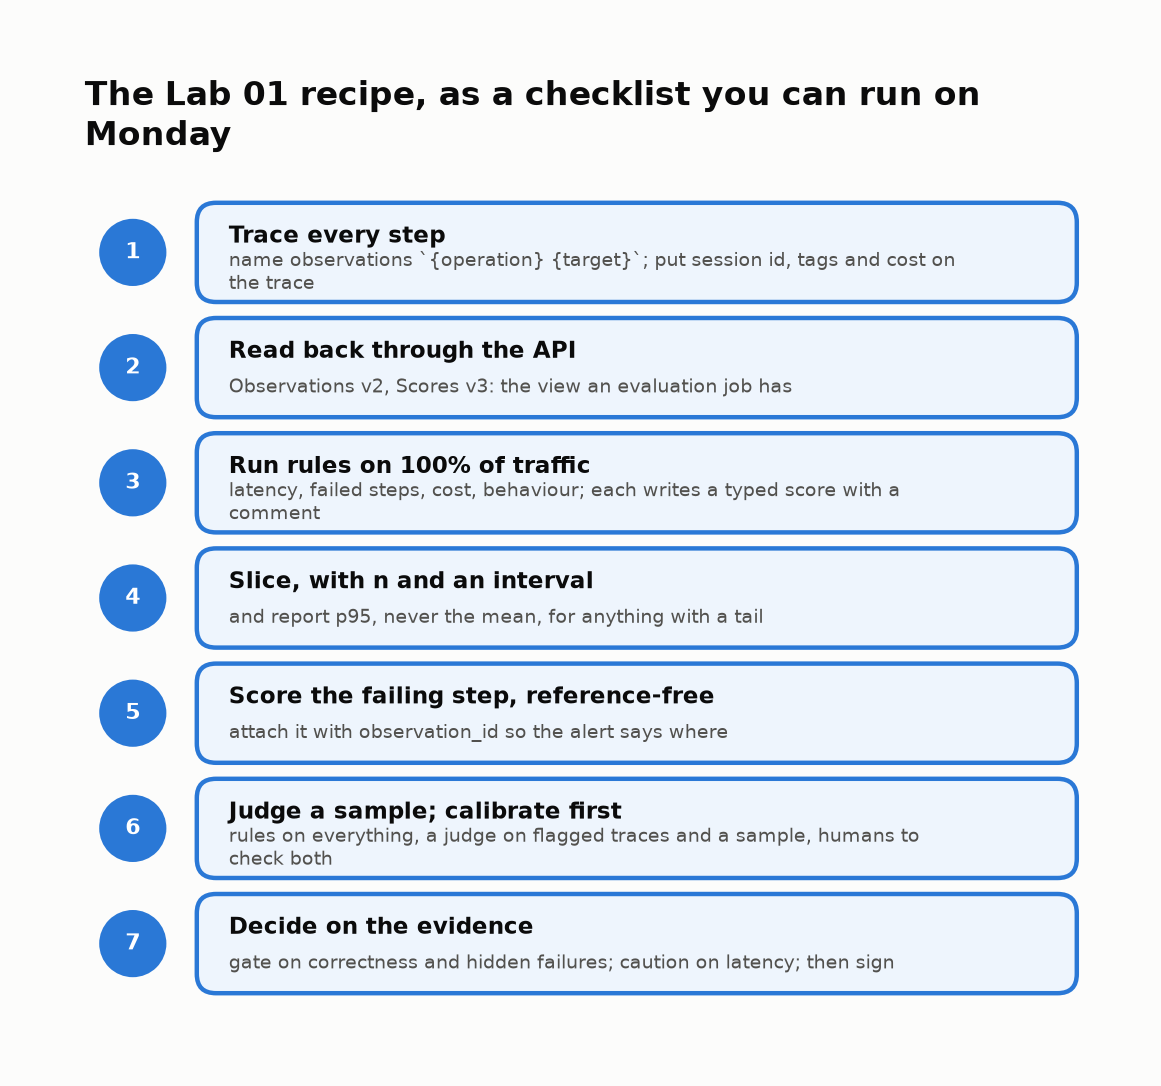
<sub>🖼️ *The lab, as a checklist.*</sub>

Beyond the ledger:

1. **Score where the evidence is**: on the trace, or on the failing observation once you know it.
2. **Use the cheapest evaluator that works**: rules for trace facts, an LLM judge for nuance, humans to calibrate both.
3. **Flush, then poll**, and read through Observations v2 and Scores v3 (`api.scores.get_many`).

---

## 💰 Is Langfuse free?

For this course, yes.

- **Langfuse Cloud** has a free **Hobby** tier: 50k billable units per month, 30 days of data access, 2 users. LLM-as-a-judge evaluators are available on every plan, including Hobby. Paid tiers are usage-based. Limits change; check [langfuse.com/pricing](https://langfuse.com/pricing).
- **Self-hosted** Langfuse is open source and runs with Docker at no licence cost; you pay for your own infrastructure. Teams self-host for data-residency or compliance reasons. SDK v5 needs a self-hosted server at v4.59.0 or later.